# SIT307 – Machine Learning

## Task 11.1HD – Machine Learning Mini Research

### Reproduction and Improvement of a Stacking-Based Ensemble for Early Heart Attack Prediction

**Student Name:** Raghav Sharma  
**Student ID:** 224816782  
**Unit:** SIT307 – Machine Learning  
**Task:** 11.1HD – Machine Learning Mini Research  

### Selected Research Paper
**Bhagat, M., Sharma, A. and Agarwal, P., “An efficient stacking-based ensemble technique for early heart attack prediction” [1].**

## Research Aim

The machine learning method described in the chosen research paper on early heart disease prediction is examined in this notebook. The machine learning experiments described in the paper are replicated in the first section of the study as nearly as feasible utilising the identical dataset, features, preprocessing techniques, and classification strategies.

Accuracy, Precision, Recall, F1 Score, and AUC are used to assess the replicated models, and the outcomes are contrasted with those presented in the original work. We look at and debate any discrepancies between the results that were published and those that were duplicated.

The second section finds a flaw in the initial methodology and creates a better machine learning strategy. The suggested approach is assessed using a repeatable experimental technique and contrasted with the published results as well as the replicated baseline.

### Research Problem, Motivation, SOTA and Research Gap

This research deals with the topic of predicting cardiac disease at early stages using machine learning. Cardiovascular disease can cause major health problems, so it is crucial to identify early those who may be at risk. The study analyses the possibility of using patient health and clinical variables using machine learning algorithms to give a more accurate prediction of heart disease [1].

The goal of this study work is to improve the prediction of heart disease using the combination of several machine learning classifiers instead of using only one model. The study compares the performance of six classifiers: Logistic Regression, Decision Tree, Random Forest, XGBoost, Naive Bayes and K-Nearest Neighbours (KNN) [1].

The selected study examines the performance of these distinct machine learning methods and then applies a stacking based ensemble method. The provided findings demonstrate multiple levels of performance for the classifiers individually. The proposed stacking strategy obtained an accuracy of 98.53%, F1 Score of 98.61% and AUC of 98.80% [1].

Previous research have used other machine learning and feature-selection algorithms for heart disease prediction. The related work in the selected paper describes an HRFLM technique with 88.47% accuracy. The combined Chi-square and PCA technique produced an accuracy of 98.7% on the Cleveland dataset, 99.0% on the Hungarian dataset and 99.4% on the combined Cleveland-Hungarian dataset [1]. Another technique with Relief feature selection and Random Forest showed an accuracy of 97.89% [1]. These prior results indicate that feature selection, ensemble approaches and combinations of machine learning techniques have already yielded robust results for heart disease prediction.

The research need addressed by the selected publication is the need to enhance the prediction of heart disease by integrating many classifiers’ prediction power instead of using one classification model. To solve this problem, the authors propose a stacking ensemble in which the predictions of several base classifiers are aggregated by a meta-classifier in an effort to obtain the final prediction [1].

## 1. Environment Setup and Reproducibility

The Python libraries needed for data processing, visualisation, machine learning, and model evaluation are imported in this section. To ensure consistent reproduction of stochastic operations across notebook runs, a fixed random seed is also defined.

Pandas, NumPy, scikit-learn, XGBoost, Matplotlib, and Seaborn are among the common machine learning libraries used in the implementation. Anywhere the chosen method accepts a `random_state` option, the same random seed will be utilised.

In [4]:
# Import the libraries needed for this study
import sys
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
# Tools for preparing the data
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
# Classification models used in the research paper
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
# Metrics used to evaluate the models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
# Use the same seed throughout the experiments
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Make the notebook output easier to read
pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore")

# Check the environment used for the experiments
print("Environment setup completed successfully.")
print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"XGBoost version: {xgboost.__version__}")
print(f"Random seed: {RANDOM_STATE}")

Environment setup completed successfully.
Python version: 3.12.3
NumPy version: 1.26.4
Pandas version: 2.2.3
Scikit-learn version: 1.5.1
XGBoost version: 3.4.1
Random seed: 42


### Discussion

All of the libraries required for this investigation were loaded without any issues, and the environment setup was completed correctly. Python 3.12.3, NumPy 1.26.4, pandas 2.2.3, scikit-learn 1.5.1, and XGBoost 3.4.1 are all used in the notebook. Because different machine learning library versions can occasionally utilise different default settings or implementations, which could alter replicated results, it is helpful to record these versions.

Additionally, I set the random seed to 42, which I will maintain throughout the notebook whenever a model or data-splitting technique allows for a `random_state`. This makes my personal tests repeatable and minimises needless variation across notebook runs, but it does not ensure that my results will match those in the published paper, particularly as the paper does not reveal every implementation detail.

This is especially crucial for this work since the goal is to compare my replicated results with those published by the authors in addition to training heart disease prediction algorithms. A more trustworthy foundation for examining any discrepancies that emerge subsequently is provided by controlling the program environment and random parameters.

Now that the environment is functioning well, the next step is to acquire the dataset from the initial study and confirm its size, characteristics, and target variable before performing any preprocessing.

## 2. Dataset Acquisition and Initial Verification

The Heart Disease Dataset, which is cited in the chosen research publication, is the dataset utilised in this investigation [1], [2]. I load the dataset and verify its dimensions, column names, and initial records before performing any preprocessing or training machine learning models.

Because the original study used 1,025 patient records and 14 features, including the target variable, this verification is crucial for the replication[1]. Before proceeding with the reproduction, it is helpful to verify that the experimental data follows the structure outlined in the paper by first checking the dataset.

In [7]:
# Load the heart disease dataset
data = pd.read_csv("heart.csv")
print("Dataset loaded successfully.")
print(f"Number of rows: {data.shape[0]}")
print(f"Number of columns: {data.shape[1]}")
print("\nColumn names:")
print(data.columns.tolist())
print("\nFirst five rows:")
display(data.head())

Dataset loaded successfully.
Number of rows: 1025
Number of columns: 14

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### Discussion
With 1,025 entries and 14 columns, the dataset loaded successfully. This is a crucial preliminary check for the reproduction because it corresponds with the dataset size stated in the chosen study [1]. Additionally, the column names indicate that the dataset has one target variable, `target`, which will be utilised for the purpose of classifying heart disease, and thirteen predictor variables.

The dataset's combination of clinical parameters and patient attributes is confirmed by the first five entries. Age and sex are among them, along with variables like the type of chest pain (`cp`), resting blood pressure (`trestbps`), cholesterol (`chol`), fasting blood sugar (`fbs`), resting ECG results (`restecg`), maximum heart rate (`thalach`), exercise-induced angina (`exang`), and ST depression (`oldpeak`). The feature set specified in the initial study also includes the remaining variables, such as `slope`, `ca`, and `thal` [1].

I have not yet changed any records or features; I have merely confirmed the data's structure. This is crucial since Part 1's goal is to replicate the original methods as precisely as feasible rather than adding further cleaning or preprocessing without first verifying what the paper truly accomplished.

Matching the dimensions is not sufficient to verify if the data is prepared for modelling, even if the number of rows and columns matches the document. The data types, missing values, duplicate observations, class distribution, and numerical ranges still need to be examined. These inspections will assist in locating any problems with the quality of the data and establishing which preprocessing procedures are appropriate for the replication.

### 2.1 Data Structure and Quality Check

Before I preprocess the dataset, I look at the data types, missing values and duplicate records. These tests allow to check for potential data-quality problems that could affect the training of models or the comparison with the published findings. I also check the unique values of the target variable to determine the type of classification problem we are replicating.

In [10]:
# Check the structure and quality of the dataset
print("Data types:")
print(data.dtypes)
print("\nMissing values:")
print(data.isnull().sum())
duplicate_count = data.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_count}")
print("\nTarget values:")
print(sorted(data["target"].unique()))
print("\nTarget class counts:")
print(data["target"].value_counts().sort_index())

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Number of duplicate rows: 723

Target values:
[0, 1]

Target class counts:
target
0    499
1    526
Name: count, dtype: int64


### Discussion


The data quality check indicates that all the 14 variables are stored in numerical form. Most of the columns use integer values. The oldpeak is maintained as a floating point variable. This allows the chosen machine learning algorithms to work directly with the dataset, rather than having to transform text-based categories to numerical values first.

No column was identified to have missing values. This makes the reproduction easier because I do not need to import an imputation approach that could make my pre-processing different from the original study. The values of the target variable are just 0 and 1, which confirms that this is a binary classification problem.

The two target classes are similarly well balanced. The dataset has 499 instances for class 0 and 526 instances for class 1, which equate to approximately 48.7% and 51.3% of the dataset, respectively. So there is no major class imbalance in this sample. I will still report Precision, Recall, F1 Score and AUC along with Accuracy as these are required for the reproduction and they give a more full perspective of model performance.

More importantly, 723 out of 1025 rows are duplicates. This is a large amount of the data collection and needs to be handled carefully. I will not delete these records in the first replication because Part 1 is intended to replicate the dataset and technique used in the published study as closely as feasible. Removing duplicates at this stage might alter the experimental data and perhaps hinder a fair reproduction of the authors’ reported results.

However, the large number of duplicate records could be a significant factor in the assessment of the model. Random splitting can lead to identical patient records being present in both the training and test sets, and a model may be evaluated on observations that are already present in its training data. This may lead to a more optimistic measured test performance than that on really unseen patient profiles. At this stage I am interpreting this as a possible methodological issue rather than presuming that it accounts for the reported findings. I will experimentally test its effect later in the notebook and utilise the evidence to critically analyse the original methods.

### 2.2 Descriptive Statistics and Feature Validation

First, the basic structure and quality of the dataset is checked. Then the descriptive statistics of the variables utilised in the study are examined. This helps to better understand the patient data before any pre-processing or machine learning algorithms are employed.

I review the number of observations, mean, standard deviation, minimum, maximum and quartile values for each variable. These statistics are helpful in understanding the overall spread and distribution of the numerical properties. They can also refer to factors that operate on extremely different scales. For example, the measurements such as cholesterol, resting blood pressure and maximum heart rate employ far greater numerical ranges than the binary or categorical variables such as sex, fasting blood sugar and exercise-induced angina. This is important because some machine learning algorithms are more sensitive than others to changes in feature scale.

This phase also allows for another opportunity to verify that the feature set utilised in my implementation is consistent with the dataset presented in the chosen research paper. The dataset includes patient characteristics and clinical measurements such as age, sex, type of chest pain, resting blood pressure, cholesterol, fasting blood sugar, resting ECG results, maximum heart rate, exercise-induced angina, ST depression, slope, number of major vessels and information about thalassaemia, along with the target variable [1].

The aim at this point is to comprehend and validate the data as it originally is, not to change it. I will thus first have a look at the descriptive statistics and utilise the observed values in combination with the technique given in the paper to select whether preprocessing procedures are appropriate for the reproduction.

In [13]:
# Calculate descriptive statistics for each variable
summary = data.describe().T

# Keep the main statistics needed for the initial analysis
summary = summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.43,9.07,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.94,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.61,17.52,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.00,51.59,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.11,23.01,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.07,1.18,0.0,0.0,0.8,1.8,6.2


### Discussion

Table 1 shows the descriptive data of the **1,025 patient records** used in the study. The patients' age ranged from **29 to 77 years** with a mean of 54.43 years. The primary clinical measures also span somewhat wide ranges. For example, **resting blood pressure (`trestbps`)** might be anywhere between 94 and 200, **cholesterol (`chol`)** between 126 and 564 and **maximum heart rate (`thalach`)** between 71 and 202. These numbers indicate that the dataset contains patients with a broad spectrum of clinical statuses.

Also, the results indicate distinct variances in the numerical scales of the attributes. For example, variables such as cholesterol and blood pressure have values in the hundreds, while `oldpeak` spans from 0 to 6.2. Other variables such as `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca` and `thal` are **categorical or binary coded variables** rather than continuous clinical measurements. This difference is significant in choosing how to prepare the data for different machine learning algorithms .

Some algorithms are more sensitive to the varied feature scales, e.g. **K-Nearest Neighbours and Logistic Regression**, while tree-based methods are often less susceptible to scaling, e.g. Trees of Decisions and Random Forests. However, I will not transform only because the variables are in different ranges. Given the methodological information available, the preprocessing employed for the reproduction should be as close as possible to the one in the original publication.

In general, the statistics corroborate the previous conclusion that the dataset is full and can be used for future study. At this point, no values will be eliminated, as there may still be genuine patient observations in the form of odd clinical measurements. Therefore the next phases will be related to comprehending the target distribution, and confirming the preprocessing approach needed for the reproduction.

### 2.3 Target Class Distribution

I check the distribution of the **target variable** before training the classification models. This allows to determine if the two classes are balanced or if the class imbalance could have an impact on the evaluation outcomes.

The target has two classes: **0 indicates absence of heart disease and 1 indicates presence of heart disease** [1]. The following table shows the number and percentage of observations in each class:

,Count,Percentage (%)
target,,
0,499,48.68
1,526,51.32


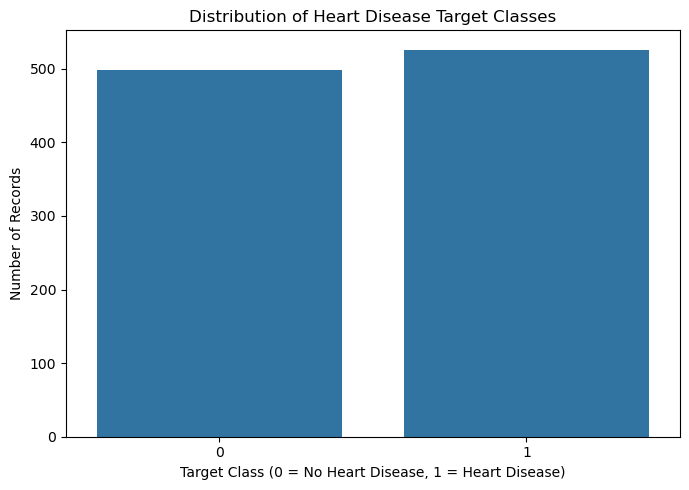

In [16]:
# Count the observations in each target class
class_counts = data["target"].value_counts().sort_index()
class_percentages = data["target"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})
display(class_summary)

# Plot the target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="target")
plt.title("Distribution of Heart Disease Target Classes")
plt.xlabel("Target Class (0 = No Heart Disease, 1 = Heart Disease)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Discussion

The target distribution reveals that the dataset is **balanced across the two classes** Class 0 has 499 records ( 48.68 % ) and class 1 has 526 records ( 51.32 % ). The difference between the two classes is minor therefore no class is dominating the dataset.

This is useful for the reproduction, as it is unlikely that a severe class imbalance will mislead the model evaluation. Hence I do not need to apply balancing methods such as oversampling or undersampling just to fix the class distribution. This would also modify the original dataset and potentially render the reproduction less comparable with the published experiment.

The classes are balanced but I will not solely depend on **Accuracy** to evaluate the models. In addition, we will additionally report **Precision, Recall, F1 Score and AUC** so that we allow the comparison of the recreated models from different aspects of classification performance. This is especially crucial for a health prediction problem when we are interested in correctly identifying positive instances besides the overall classification accuracy.

### 2.4 Reproduction Protocol from the Original Paper

I looked at the experimental approach of the publication I chose before preprocessing or splitting the dataset. This is significant because **Part 1 aims to recreate the published experiment**, not to build a new modelling process based on my own decisions.

The research proposes a strategy of preprocessing data, feature selection, training of six separate classifiers, and a stacking ensemble**. The individual classifiers include **Logistic Regression (LR), Decision Tree (DT), Random Forest (RF), XGBoost, Naive Bayes (NB) and K-Nearest Neighbours (KNN)** [1].

The paper also deals with feature selection and examines the relative value of the input qualities [1]. However, it does not disclose the sufficient implementation information to reproduce a conclusive reduced feature subset. Thus, the reproduction has the 13 predictor features accessible in the data set.

Therefore I shall break the reproduction down into clearly documented steps. Wherever the article provides a clear procedure I will follow it as closely as possible. In case the implementation details are not provided or not clear, I will state the assumption that I am making in this notebook, so as to keep the reproduced results transparent and reproducible.

### 2.5 Reproduction Decisions and Assumptions

To fairly replicate the original study, I split the technique into features that are **accurately stated in the paper** and details that are **not fully defined**. This is significant, because the introduction of undocumented decisions without explanation could make the duplicated results appear more directly comparable with the published results than they are.

In this paper, a dataset of **1,025 patient records and 14 variables** including the target, is presented. It trains six individual classifiers: **Logistic Regression, Decision Tree, Random Forest, XGBoost, Naive Bayes and K-Nearest Neighbours** and then applies a **5-fold stacking ensemble** [1]. These elements will so be maintained in the reproduction.

However, the document does not give enough information to precisely recover each implementation configuration. More specifically, the available technique does not explicitly define the **random seed, full hyperparameter settings for each classifier, or all aspects of the train-test split and stacking configuration.** If I don't have such information, I shall make explicitly stated and reproducible assumptions rather than trying to guess undocumented parameters.

Where possible I will use a fixed **random seed of 42** to ensure that my own results can be repeated consistently. We shall state any new assumptions added during preprocessing, model training or evaluation at the point of usage. This disparity between **reported technique and reproduction assumptions** will also be considered when analysing differences between my results and those stated by the authors.

## 3. Experimental Data Preparation

After validating the dataset and writing down the reproduction assumptions, the following step is to prepare the data for the machine learning trials. This part aims to generate the **predictor matrix (`X`)** and **target vector (`y`)**. It also defines a reproducible training and testing strategy and prepares the data in a manner suitable for the classifiers employed in the original study.

The `target` column is the outcome that the models will try to predict. The other **13 variables are used as predictor features** [1]. To ensure that the experimental dataset is identical to the one analysed in the previous section, I retain the whole set of 1,025 records for the first replica.

A major concern detected in the initial study is the presence of a substantial number of **duplicate observations**. I shall not delete these entries before I create the recreated baseline. Rather I will keep the original data set for Part 1 and measure independently if the same observations occur in the training and test sets. This will allow the effect of duplicate overlap to be explored from experimental evidence rather than assumed a priori.

All experimental choices not explicitly described by the study will be replicable and well documented. Thus, the same **random seed of 42** set previously will be utilised where a random state is needed.

### 3.1 Separating the Features and Target

First, the dataset is split into the **input features (`X`)** and the **target variable (`y`)**. We drop the `target` column from the predictor matrix, so that it cannot be utilised as an input during training of the model.

In [22]:
# Separate the predictor features from the target
X = data.drop(columns=["target"])
y = data["target"]
print("Feature and target separation completed.")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print("\nPredictor features:")
print(X.columns.tolist())
print("\nTarget classes:")
print(sorted(y.unique()))

Feature and target separation completed.
X shape: (1025, 13)
y shape: (1025,)

Predictor features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target classes:
[0, 1]


### Discussion

The feature and target separation was done correctly. The predictor matrix `X` has **1,025 observations and 13 input features** and `y` has the corresponding **1,025 target values**. This shows that all patient records were kept and the `target` variable was not unintentionally used as an input feature.

The predictor set consists of the clinical and patient variables described earlier, such as **age, chest pain type, resting blood pressure, cholesterol, maximum heart rate, exercise-induced angina and oldpeak**, as well as the other coded features. The aim is still merely **0 and 1**. So the problem is still a binary classification task.

This separation also avoids ** goal leakage **, since the outcome the models are supposed to predict is separated from the predictor variables . The obtained `X` and `y` are now used to construct the training and test sets for the reproduction experiments.

### 3.2 Train-Test Split and Duplicate-Overlap Check

Next  we will split the dataset into **training and test sets**. The training set is used to fit the standard ML models, while the test set is held out and used to evaluate how well the fitted models perform on observations not utilised in fitting the models.

A ** stratified split** is used to keep the ratio of the two target classes roughly the same in the two subsets. I also specify the previously defined **random seed of 42** so that the same split may be replicated every time the notebook is run.

The extra check is included since the last data-quality analysis found **723 duplicate rows** in the full dataset. Once the split is done, I examine whether there are identical feature-target records in the training and test sets. This does not affect the reproduced dataset, it is a diagnostic procedure that will help to assess whether duplicate observations could influence the evaluation of the baseline models.

In [25]:
# Create reproducible training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Train-test split completed.")
print(f"Training set: {X_train.shape[0]} records")
print(f"Test set: {X_test.shape[0]} records")

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(4))
# Check whether identical complete records occur in both sets
train_records = X_train.copy()
train_records["target"] = y_train

test_records = X_test.copy()
test_records["target"] = y_test

overlap = test_records.merge(
    train_records.drop_duplicates(),
    how="inner"
)
overlapping_test_rows = test_records.index[
    test_records.apply(
        lambda row: (
            train_records == row
        ).all(axis=1).any(),
        axis=1
    )
]
print("\nDuplicate-overlap check:")
print(f"Unique complete records shared across train and test: {len(overlap.drop_duplicates())}")
print(f"Test rows with an identical record in training: {len(overlapping_test_rows)}")
print(
    f"Percentage of test rows represented in training: "
    f"{len(overlapping_test_rows) / len(test_records) * 100:.2f}%"
)

Train-test split completed.
Training set: 820 records
Test set: 205 records

Training target distribution:
target
0    0.4866
1    0.5134
Name: proportion, dtype: float64

Test target distribution:
target
0    0.4878
1    0.5122
Name: proportion, dtype: float64

Duplicate-overlap check:
Unique complete records shared across train and test: 155
Test rows with an identical record in training: 202
Percentage of test rows represented in training: 98.54%


### Discussion

The **80/20 stratified split** resulted in 820 training records and 205 test records. The class ratios were very much alike in both subsets with about **51% positive and 49% negative cases**. This confirms that stratification has effectively kept the original target distribution and avoids producing a class-balance discrepancy between training and testing.

The duplicate-overlap check pointed out a much more important issue. There are **155 distinct full records in the training and test sets**, and **202 out of the 205 test observations (98.54%) have an exact record in the training data**. Thus, despite random separation of the rows, practically the entire test set is represented by identical observations already existent at the time of model training.

This is a severe concern in the interpretation of the baseline evaluation. A test set is used for measuring performance on unseen observations . High test performance may be partly due to identical records being in both sets, reflecting a model's exposure to the same patient profiles, rather than its capacity to generalise to really unseen profiles. But this conclusion alone does **not determine the extent to which the model ratings are inflated. That has to be proven by experiment . *

For **Part 1** I will leave this divide as is so the baseline reproduction still uses the full 1,025-record dataset. I then compare these baseline findings to an evaluation technique in which identical records do not cross between training and testing at a later point in time. This will provide direct evidence as to whether duplication overlap significantly affects reported performance, and may present a substantial methodological limitation to study in Part 2.

### 3.3 Feature Scaling

It was found via the descriptive analysis that the predictor variables are on **different numerical scales**. For example, cholesterol and resting blood pressure are in the hundreds while variables such as `oldpeak` and the category aspects with number codes have significantly narrower numerical ranges. This discrepancy could affect algorithms that rely on distances or the relative size of feature values.

The feature scaling has to be done as well for the replication without any **data leakage** . Thus, the scaling parameters have to be learned on **training data only** and then applied unchanged to the test data. Using information from the test set when fitting a scaler would allow the training pipeline to indirectly employ information from the data allocated for assessment. 

As the actual scaling implementation needs to be consistent with the approach described in the selected paper, the transformation applied below will be explicitly specified. The same modified training and test sets are then routinely used for evaluating models that require scaled inputs.

In [28]:
# Min-Max normalisation of the training and test data
from sklearn.preprocessing import MinMaxScaler
# Create the scaler
scaler = MinMaxScaler()
# Fit only on the training data to avoid data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Convert back to DataFrames so the original feature names are retained
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)
print("Feature scaling completed.")
print(f"Scaled training shape: {X_train_scaled.shape}")
print(f"Scaled test shape: {X_test_scaled.shape}")
print("\nFirst five rows of the scaled training data:")
display(X_train_scaled.head())
print("\nMinimum values of scaled training features:")
display(X_train_scaled.min().round(3))
print("\nMaximum values of scaled training features:")
display(X_train_scaled.max().round(3))

Feature scaling completed.
Scaled training shape: (820, 13)
Scaled test shape: (205, 13)

First five rows of the scaled training data:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
4,0.687500,0.0,0.000000,0.415094,0.383562,1.0,0.5,0.267176,0.0,0.306452,0.5,0.75,0.666667
688,0.562500,0.0,0.000000,1.000000,0.369863,1.0,0.0,0.473282,1.0,0.645161,0.0,0.50,1.000000
477,0.583333,1.0,0.666667,0.320755,0.235160,0.0,0.0,0.603053,0.0,0.064516,0.5,0.25,1.000000
336,0.583333,1.0,0.666667,0.528302,0.000000,1.0,0.5,0.778626,0.0,0.032258,1.0,0.25,1.000000
960,0.479167,0.0,0.666667,0.396226,0.159817,0.0,0.0,0.748092,0.0,0.016129,0.5,0.00,0.666667



Minimum values of scaled training features:


age         0.0
sex         0.0
cp          0.0
trestbps    0.0
chol        0.0
fbs         0.0
restecg     0.0
thalach     0.0
exang       0.0
oldpeak     0.0
slope       0.0
ca          0.0
thal        0.0
dtype: float64


Maximum values of scaled training features:


age         1.0
sex         1.0
cp          1.0
trestbps    1.0
chol        1.0
fbs         1.0
restecg     1.0
thalach     1.0
exang       1.0
oldpeak     1.0
slope       1.0
ca          1.0
thal        1.0
dtype: float64

### Discussion

The results of the scaling process verify that the 13 predictor features were Min-Max normalised. The training features were scaled in the range [0, 1].

The scaler was fit only on the 820 training data and applied to the 205 test records. This is done to avoid information from the test set getting into the pre-processing stage and to limit the possibility of data leakage.

The chosen study mentions normalisation as a part of the preprocessing approach, although does not clearly mention the exact normalisation implementation [1]. Therefore, Min-Max normalisation was applied in this reproduction as a documented and reproducible assumption. Models sensitive to feature magnitude were trained on scaled data, while tree-based models were trained on original unscaled data.

### 3.3.1 Preprocessing Comparison for Logistic Regression

Missing values are treated and scaled by the authors, but there is not enough information provided to reproduce the exact preprocessing steps. My initial implementation of Logistic Regression utilized Min-Max scaling. In order to see the effect of this specific choice, I will compare the model implemented with the Min-Max scaling to standard scaling and median imputation with standard scaling. I will keep the exact same training-test data split and Logistic Regression configuration for both models.

In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# Keep the model settings the same so that I can compare
# the effect of preprocessing on the same train/test split.
preprocessing_methods = {
    "Min-Max scaling": make_pipeline(
        MinMaxScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Standard scaling": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Median imputation + standard scaling": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )
}

results = []

for method_name, model in preprocessing_methods.items():
    # The pipeline learns preprocessing values from the training data only.
    model.fit(X_train, y_train)

    # Use the same test records to assess each method.
    predictions = model.predict(X_test)
    positive_probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Preprocessing": method_name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(y_test, predictions) * 100,
        "Recall": recall_score(y_test, predictions) * 100,
        "F1 Score": f1_score(y_test, predictions) * 100,
        "AUC": roc_auc_score(y_test, positive_probabilities) * 100
    })

# Show all five metrics as percentages for an easier comparison.
preprocessing_results = pd.DataFrame(results)
display(preprocessing_results.round(2))

# Check whether imputation had any missing values to fill.
print("Missing values in the dataset:", data.isna().sum().sum())

,Preprocessing,Accuracy,Precision,Recall,F1 Score,AUC
0,Min-Max scaling,83.41,79.34,91.43,84.96,92.86
1,Standard scaling,80.98,76.19,91.43,83.12,92.98
2,Median imputation + standard scaling,80.98,76.19,91.43,83.12,92.98


Missing values in the dataset: 0


### Discussion

Three different preprocessing techniques were applied using the same train-test split and logistic regression parameters. With Min-Max scaling, I received an accuracy rate of 83.41%, and with standard scaling, an accuracy rate of 80.98%. Applying the median imputation method together with standard scaling did not make any difference as there are no missing values in the data set.

The paper mentions accuracy rate of 84.39% for Logistic Regression. However, this does not mean that the authors used Min-Max scaling technique since their preprocessing procedure is not explicitly explained and changing only scaler did not produce the same results.

## 4. Reproduction of Individual Classifiers

Having generated the dataset, I re-train the **six individual machine learning classifiers** evaluated in the selected study: **Logistic Regression (LR), Decision Tree (DT), Random Forest (RF), XGBoost, Naive Bayes (NB) and K-Nearest Neighbours (KNN)** [1].

In an effort to make the comparison fair, we train each classifier on the same training and test partition generated in the previous section. The evaluation is based on **Accuracy, Precision, Recall, F1 Score and AUC** that let to compare the replicated results on multiple areas of classification performance rather than using accuracy alone.

The publication does not include all of the implementation level hyperparameters, which are necessary to exactly reproduce each classifier. In the absence of an expressly disclosed setting, I therefore employ a **well-documented and reproducible implementation choice**, rather than trying to guess the authors’ configuration. The same random seed is utilised for models using randomisation.

For models sensitive to the magnitude of features like **Logistic Regression and KNN**, I utilise the scaled training and test data provided in Section 3.3. Tree-based models are trained on the original feature values because the split process does not depend directly on the numerical scale of the predictors.

The results of the six distinct classifiers are first considered independently and then summed in a common comparison table. This offers the baseline to replicate the paper's **stacking ensemble**.

### 4.1 Model Evaluation Function

To compare all classifiers on an equal footing, I build a function that can be reused to compute the performance measurements that I need. The function outputs **Accuracy, Precision, Recall, F1 Score and AUC** and saves the results so all models can be compared in one table later.

AUC uses the predicted probabilities rather than the final class labels, because AUC indicates how well the model ranks positive and negative observations across different categorisation thresholds.

In [35]:
# Store the performance of each reproduced model
model_results = []
def evaluate_model(name, model, X_eval, y_eval):
    """Evaluate a fitted binary classification model."""
    y_pred = model.predict(X_eval)
    # Use positive-class probabilities for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred),
        "Recall": recall_score(y_eval, y_pred),
        "F1 Score": f1_score(y_eval, y_pred),
        "AUC": roc_auc_score(y_eval, y_score)
    }
    model_results.append(results)
    print(f"{name} Results")
    print("-" * 35)
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1 Score : {results['F1 Score']:.4f}")
    print(f"AUC      : {results['AUC']:.4f}")
    return y_pred, y_score

### 4.2 Logistic Regression

The first recreated individual classifier is **Logistic Regression (LR)**. Logistic Regression calculates the chance that an observation belongs to the positive class, and is widely used as a baseline for binary classification issues.

For this experiment, I used the **scaled training and test data** from Section 3.3 because Logistic Regression can be sensitive to the different magnitudes of features. The model is trained just on the training set and evaluated on the held-out test set.

The recreated model is assessed using **Accuracy, Precision, Recall, F1 Score and AUC** based on the evaluation framework set before. This performance will be compared subsequently with the other individual classifiers and with the results presented in the selected publication.

In [37]:
# Create and train the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
lr_model.fit(X_train_scaled, y_train)
# Evaluate the model on the test set
lr_pred, lr_score = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_test_scaled,
    y_test
)

Logistic Regression Results
-----------------------------------
Accuracy : 0.8341
Precision: 0.7934
Recall   : 0.9143
F1 Score : 0.8496
AUC      : 0.9286


### Discussion

The re-created Logistic Regression model was able to reach an Accuracy of **83.41%** which means that it properly classified more than four out of five records in the test set.

The model reported a Precision of **79.34%** and Recall of **91.43%**. The higher Recall suggests that the model was able to detect most of the positive heart-disease cases, but the lower Precision indicates that some negative cases were improperly labelled as positive. The F1 Score of ** 84.96 % ** is the resulting number giving a balance between Precision and Recall.

The model also achieved an AUC of ** 92.86 % ** , showing good discrimination between the two target classes at different classification thresholds . However, the results should be regarded with caution, as the duplication analysis revealed a large overlap between the baseline training and test sets. Thus, this result reflects the performance of the recreated baseline experiment, not the performance on wholly unseen patient profiles.

#### 4.2.1 Confusion Matrix and ROC Curve

In addition to the summary metrics, I utilise a confusion matrix and a ROC curve to explore the **Logistic Regression** model. The confusion matrix gives the distribution of the predictions over **true positives, true negatives, false positives and false negatives** while the ROC curve illustrates the ability of the model to discriminate between the two classes at different classification thresholds.

These visualisations assist explain the performance seen in the preceding section, in particular the relatively high **Recall** and **AUC** of the models.

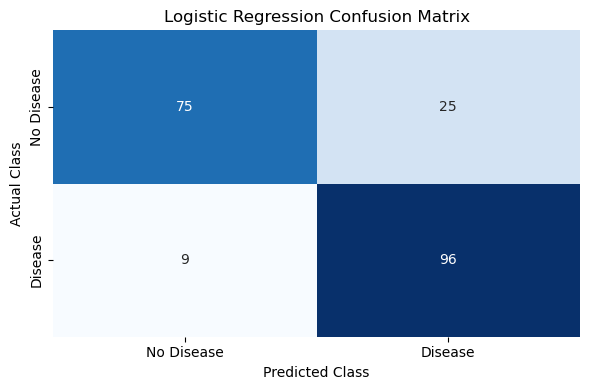

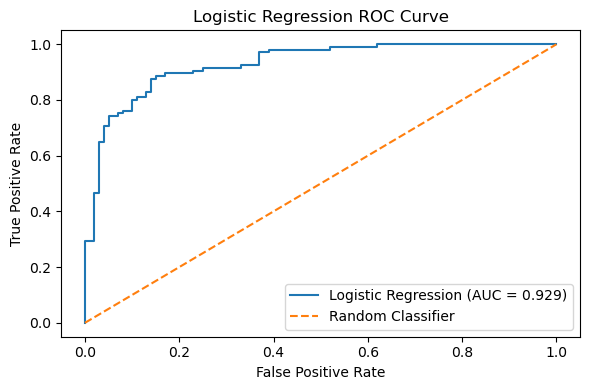

In [40]:
# Create the confusion matrix
lr_cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# Calculate and plot the ROC curve
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_score)
lr_auc = roc_auc_score(y_test, lr_score)
plt.figure(figsize=(6, 4))
plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("Logistic Regression ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

### Discussion


The confusion matrix gives a more clear overview of the predictions of the Logistic Regression model. The model was able to classify **75 patients without heart disease** and **96 patients with heart disease out of 205 test records. It **misidentified 25 negative cases as positive** and **9 positive cases as negative**.

The comparatively low number of false negatives leads to a high **Recall of 91.43%**, which means that the model detected most of the heart-disease positive cases. The **Precision of 79.34%** shows that some of the patients predicted as positive were negative.

The ROC curve yields a **AUC of ~92.86%** which indicates the good capacity of Logistic Regression to distinguish between the two classes at different classification thresholds. However, these results are still from the baseline experiment with large duplicate overlap, thus the following duplicate-controlled trial provides a more strict evaluation of the model performance.

### 4.3 Decision Tree

The second individual classifier that is repeated is the **Decision Tree (DT)**. A Decision Tree classifies by successively partitioning the data based on feature values, producing a tree of decision rules that divide the target classes.

Decision tree models are typically **not affected by feature scaling**, unlike Logistic Regression and KNN. This is because they employ split points that are particular to each feature, rather than distances between observations. So, I train this model with the **original unscaled training and test data**.

Decision Tree is one of the six individual classifiers in the paper under consideration. When the paper does not disclose sufficient implementation-level details, I employ a replicable implementation and explicitly consider these details as assumptions, rather than ascribing them to the authors. The model is evaluated with the same ** Accuracy, Precision, Recall, F1 Score and AUC ** measures used for Logistic Regression so that the classifiers may be compared on the same basis.

In [43]:
# Create and train the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)
dt_model.fit(X_train, y_train)
# Evaluate the model on the test set
dt_pred, dt_score = evaluate_model(
    "Decision Tree",
    dt_model,
    X_test,
    y_test
)

Decision Tree Results
-----------------------------------
Accuracy : 0.9854
Precision: 1.0000
Recall   : 0.9714
F1 Score : 0.9855
AUC      : 0.9857


#### Discussion

The recreated **Decision Tree** has very good performance, with a **Accuracy of 98.54%**, **Precision of 100.00%**, **Recall of 97.14%**, **F1 Score of 98.55%**, and **AUC of 98.57%**. These findings are far greater than the values produced by the Logistic Regression model.

The **100% Precision** signifies that all test observations labelled as heart disease were indeed from the positive class. At the same time, the **97.14% Recall** implies that the model detected almost all of the true positives. The comparable Accuracy, F1 Score and AUC values indicate consistently high performance across multiple evaluation metrics rather than strong performance according to only one metric

However, this very high performance needs to be taken with caution. Earlier study has shown that **98.54% of the test rows have an exact pair in the training data**. A flexible model like Decision Tree can learn complex decision rules from the training observations. Repeated records across the split may render the test task far easier than classification of truly unseen patient profiles. So I don't read the 98.54% Accuracy as proof of equal generalisation in the real-world.

This finding renders the duplicate record problem particularly relevant for the next critical appraisal. A more rigorous experiment that does not allow duplicate observations to cross the training and test sets will shed light on how much of this apparent performance is maintained when the model is tested on truly separated records.

#### 4.3.1 Confusion Matrix and ROC Curve

The individual classifications of the **Decision Tree** are analysed with the confusion matrix and the discriminating between the two target classes is shown in the ROC curve. These output are very important to investigate the very high performance in the numerical findings.

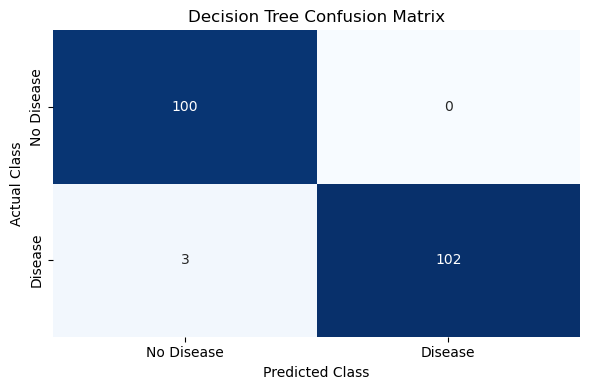

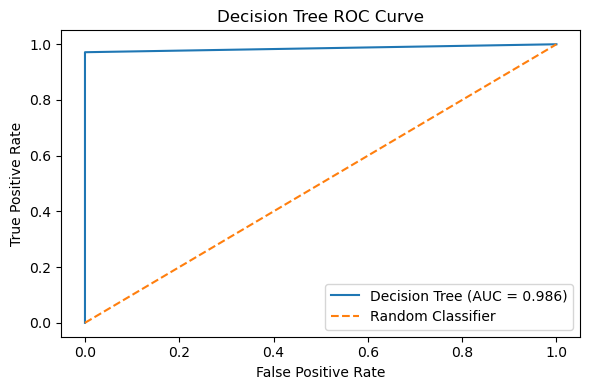

In [46]:
# Create the Decision Tree confusion matrix
dt_cm = confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# Calculate and plot the Decision Tree ROC curve
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_score)
dt_auc = roc_auc_score(y_test, dt_score)
plt.figure(figsize=(6, 4))
plt.plot(
    dt_fpr,
    dt_tpr,
    label=f"Decision Tree (AUC = {dt_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("Decision Tree ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

#### Discussion

From the confusion matrix, it was seen that the **Decision Tree** properly classified **100 patients without heart disease** and **102 patients with heart disease** There were **0 false-positive predictions** and only **3 positive patients were wrongly labelled as no cardiac disease**. This directly accounts for the model’s **100% Precision** and exceptionally high **Recall of 97.14%**.

The Decision Tree made much less classification errors on this test set than Logistic Regression did. Specifically, Logistic Regression had 25 false positives and 9 false negatives, while the Decision Tree had 0 false positives and only 3 false negatives. This justifies the huge improvement in Accuracy from **83.41% to 98.54%**.

The ROC curve likewise has a very good discrimination with a **AUC of about 0.986**. The curve goes up in the top-left part of the plot, showing that for the categorisation scores available, the true-positive rate is high while the false-positive rate is very low.

Although these results seem to be outstanding, they should not be construed as evidence that the Decision Tree would perform similarly on new patient data. The previous duplicate analysis revealed considerable overlap between training and test records. So this near perfect confusion matrix does make a strong case for the subsequent duplicate-controlled experiment, where I will test whether this performance holds when identical records are kept from appearing throughout the training and test sets.

### 4.4 Random Forest


The third individual classifier implemented is the **Random Forest (RF)**. Random Forest is an ensemble learning method that combines the predictions of numerous decision tree models. Every tree is trained on a sampled version of the training data and considers subsets of features in the splitting phase. Combining several trees reduces the instability and overfitting that comes with relying on a single Decision Tree.

Similar to the Decision Tree, Random Forest does not need feature scaling because it makes predictions based on tree splits rather than distances between observations. So I utilise the **original unscaled training and test data**.

The chosen study employs Random Forest as one of the individual classifiers to be employed prior to building the stacking ensemble. Where the paper does not sufficiently provide settings at implementation level, I do not assume undocumented parameters, but rather that there is a reproducible implementation. We set the **random seed to 42** so that the experiment can be reproducted in the same way.

The model is assessed by the same **Accuracy, Precision, Recall, F1 Score and AUC** metrics as the prior classifiers.

In [49]:
# Create and train the Random Forest model
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE
)
rf_model.fit(X_train, y_train)
# Evaluate the model on the test set
rf_pred, rf_score = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

Random Forest Results
-----------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000
AUC      : 1.0000


#### Discussion

The recreated **Random Forest** attained **100% Accuracy, Precision, Recall, F1 Score and AUC** on the test set. This means that with the current experimental split, all test observations have been correctly classified, and no classification mistakes of the model have been noticed.

This is a big improvement over Logistic Regression and also a bit better than the very strong Decision Tree result. The result implies that the ensemble of many decision tree models was able to fit the patterns of this particular training and test configuration exceedingly well.

But a perfect test result should be taken with a good deal of caution and not automatically as evidence of perfect prediction ability. In the previous analysis we found that **98.54% of the rows in the test set had a corresponding row in the training set**. Random Forest is a flexible tree-based ensemble and the presence of duplicated observations across the two sets can make the test data considerably less independent from the training data than would be expected.

Therefore, the **100% test performance is a result of this replicated experimental setup, and not a sign that the classifier would achieve 100% performance when applied to truly unseen patients**. This discovery makes the later duplicate-controlled evaluation much more essential, as it will provide a more robust test of whether the apparent performance survives when identical records are not allowed to cross the train-test boundary.

#### 4.4.1 Confusion Matrix and ROC Curve

To further investigate the ideal numerical performance, I utilise a **confusion matrix** to analyse the individual Random Forest forecasts and a **ROC curve** to evaluate its discrimination across classification thresholds.

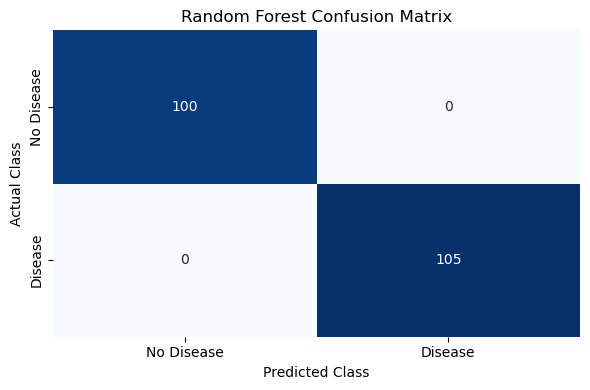

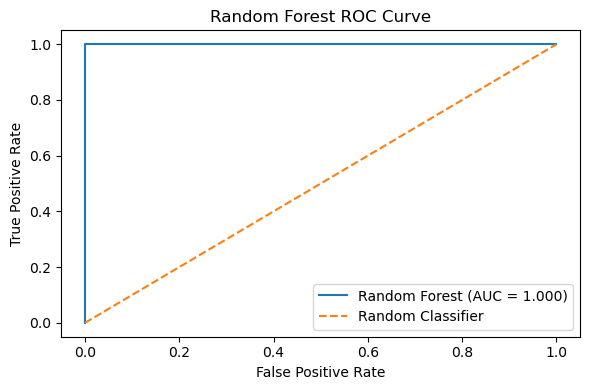

In [52]:
# Create the Random Forest confusion matrix
rf_cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# Calculate and plot the Random Forest ROC curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_score)
rf_auc = roc_auc_score(y_test, rf_score)

plt.figure(figsize=(6, 4))
plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("Random Forest ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

#### Discussion

The confusion matrix indicates flawless numerical performance for the **Random Forest** model. All **100 patients without heart disease** were accurately classified as negative. All **105 patients with heart disease** were appropriately classified as positive. There were no false positives and no false negatives in this test set.

The ROC curve is likewise consistent with these results where it reaches the upper-left corner of the plot and yields a **AUC of 1.000**. This particular train-test split resulted in perfect separation of the two target classes by the Random Forest.

While this is the best result produced so far, it should be taken with caution. A complete confusion matrix on a held-out test set would generally indicate very excellent prediction performance, yet the previous study demonstrated that **98.54% of the test rows are represented by identical records in the training data**. This indicates the test set is not offering a very good measure of performance on completely unseen patient profiles.

Therefore, the ideal Random Forest finding is beneficial to reproduce the behaviour of the current experimental setup, but should not be considered as evidence of flawless real-world generalisation. The next experiment of duplicate-controlled experiment will be a more challenging assessment of the model.

### 4.5 XGBoost

The fourth reproduced individual classifier is **XGBoost (Extreme Gradient Boosting) **. Random forest generates many trees , and combines their predictions . Trees are built primarily independently of each other . XGBoost builds trees sequentially . Each subsequent tree tries to fix the mistakes of the current ensemble, which lets the model learn complicated correlations between the input features and the target.

XGBoost is one of the single classifiers in the selected study. Like the other tree based approaches I employ the **original unscaled feature data**, as decision-tree splits do not require predictors to be standardised.

If the publication does not describe implementation details sufficiently to accurately duplicate every XGBoost hyperparameter, I instead utilise a properly documented and reproducible implementation, rather than assuming undocumented values. We use the same **random seed of 42** for consistency with earlier trials.

The model is tested on the same held-out test set using **Accuracy, Precision, Recall, F1 Score and AUC** so its performance can be directly compared with Logistic Regression, Decision Tree and Random Forest.

In [55]:
# Create and train the XGBoost model
xgb_model = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss"
)
xgb_model.fit(X_train, y_train)

# Evaluate the model on the test set
xgb_pred, xgb_score = evaluate_model(
    "XGBoost",
    xgb_model,
    X_test,
    y_test
)

XGBoost Results
-----------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000
AUC      : 1.0000


#### Discussion

The replicated **XGBoost** model obtained **100% Accuracy, Precision, Recall, F1 Score and AUC** on the existing test set. Hence, in this setting of the experiment all test observations were correctly identified. Its performance is comparable to the ideal result given by Random Forest and better than the results produced by Logistic Regression and the single Decision Tree.

The excellent Precision and Recall show that the model did not make any false-positive or false-negative classification errors at the chosen decision threshold. The **AUC of 1.000** further implies a full separation of the two classes based on the prediction scores on this test set.

However, this result needs to be interpreted just as carefully as the Random Forest result. From the duplicate analysis above, we have demonstrated that **98.54% of the test rows are covered by exact records in the training data**. Since XGBoost is a versatile boosting model capable of learning complicated patterns, this large overlap could make the held-out test set much easier to identify than truly unseen patient records.

This is why the perfect outcome is the performance of the ** replicated baseline experiment ** , not evidence that XGBoost would produce perfect predictions of new patients . The later duplicate-controlled evaluation will be vital to see how much of this performance persists under a stronger train-test separation.

#### 4.5.1 Confusion Matrix and ROC Curve

To further investigate the perfect XGBoost result, I use a **confusion matrix** to verify the individual predictions and a **ROC curve** to verify the capacity of the model to discriminate between the two classes at classification thresholds.

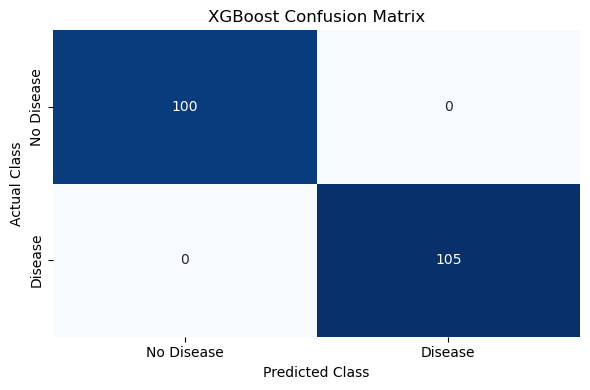

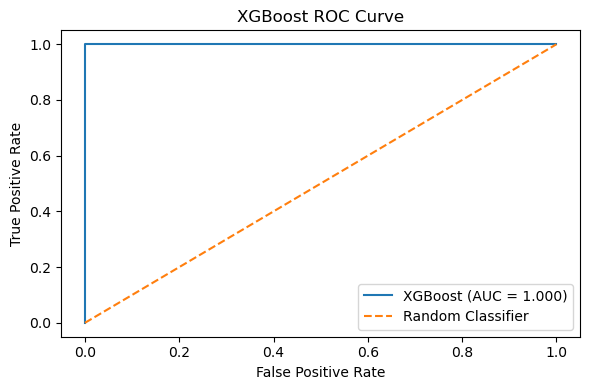

In [58]:
# Create the XGBoost confusion matrix
xgb_cm = confusion_matrix(y_test, xgb_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# Calculate and plot the XGBoost ROC curve
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_score)
xgb_auc = roc_auc_score(y_test, xgb_score)

plt.figure(figsize=(6, 4))
plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("XGBoost ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

#### Discussion

The confusion matrix shows **XGBoost identified all 205 test observations correctly.** The model properly predicted all **100 patients without heart disease** as negative and all **105 patients with heart disease** as positive. There were ** no false-positive or false-negative predictions ** which explains the 100 % Accuracy, Precision, Recall and F1 Score achieved above.

Also, the ROC curve shows the same general view with a **AUC of 1.000** and the curve goes to the upper-left portion of the figure. So the prediction scores are perfect separation of positive and negative groups on this test set.

This result is same as Random Forest result and better than single Decision Tree and Logistic Regression outcomes. However, the perfect classification still needs to be understood in light of the previously found **98.54% duplicate overlap between the training and test records**. The data show that XGboost works properly under the existing baseline split but they do not prove that the model would work equally well on really unseen patient records.

### 4.6 Naive Bayes


The next classifier we reproduce is **Gaussian Naive Bayes**. This model is derived on Bayes theory and assumes conditional independence of the predictor characteristics given the target class. The continuous features are modelled with Gaussian densities.

The same baseline training and test sets are used to train the model as for the other individual classifiers so that the model’s performance can be compared under the same experimental settings . The model is evaluated using **Accuracy, Precision, Recall, F1 Score and AUC** and then we present the confusion matrix and the ROC curve of the model.

In [61]:
# Create and train the Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
# Evaluate the model on the test set
nb_pred, nb_score = evaluate_model(
    "Naive Bayes",
    nb_model,
    X_test,
    y_test
)

Naive Bayes Results
-----------------------------------
Accuracy : 0.8293
Precision: 0.8070
Recall   : 0.8762
F1 Score : 0.8402
AUC      : 0.9043


#### Discussion

The **Naive Bayes model attained an accuracy of 82.93%**, which is a really excellent classification result on the baseline test set. **Precision = 80.70%**: This shows that most of the patients projected to have heart disease are really categorised accurately. However, there are false positive predictions as well.

The model achieved a recall of 87.62% implying that it was able to correctly identify a large proportion of the patients that truly had heart disease. The resulting **F1 Score of 84.02%** suggests a reasonable trade-off between precision and recall.

The **AUC of 0.9043** likewise shows good separation between the two target classes. However, there is no question that Naive Bayes is below the tree-based models obtained above, especially Random Forest and XGBoost. Just as with the earlier baseline results, these numbers must also be taken with caution, due to the significant duplicate overlap found before between the training and test data.

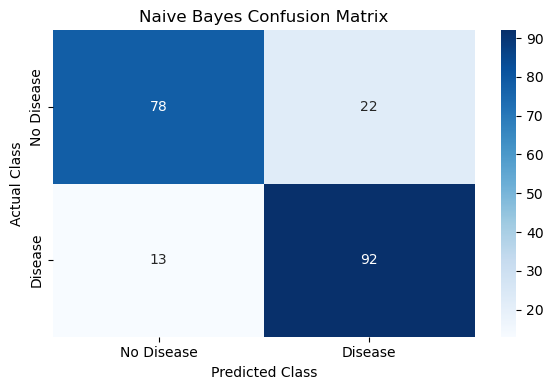

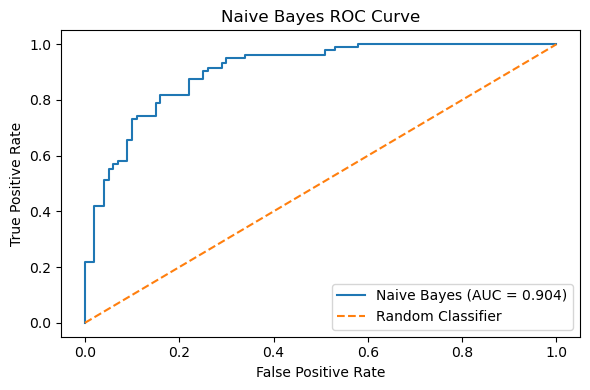

In [63]:
# Confusion matrix for Naive Bayes
nb_cm = confusion_matrix(y_test, nb_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# ROC curve for Naive Bayes
nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_score)
nb_auc = roc_auc_score(y_test, nb_score)
plt.figure(figsize=(6, 4))
plt.plot(
    nb_fpr,
    nb_tpr,
    label=f"Naive Bayes (AUC = {nb_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("Naive Bayes ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

#### Discussion

The confusion matrix provides a better view of the outcomes of **Naive Bayes**. The model accurately identified ** 78 ** of the ** 100 patients without heart disease. ** However, it mistakenly predicted ** 22 to have heart disease. ** ** 105 patients who truly had heart disease ** . The model was able to accurately identify ** 92 patients ** . ** 13 patients were wrongly labelled as not having the condition ** .

This explains why the model has a reasonably high **Recall of 87.62%** but a rather low **Precision of 80.70%**. The program proved rather good at identifying people with heart disease, but also made a significant amount of false-positive predictions. In this dataset it consequently seems to be marginally better at recognising positive cases than avoiding inaccurate positive predictions.

The **ROC curve is far above the random-classifier line**, with **AUC of 0.904**, which means that Naive Bayes has high ability to discriminate between the two classes for different classification thresholds. The performance is considerably behind the near flawless results from some of the tree based models but it still provides a valuable individual classifier for comparison.

As with the prior models, these results should not be interpreted as evidence of equally good performance on wholly unseen patients. The previous duplicate analysis revealed a lot of overlap between the baseline training and test sets, hence the later **duplicate-controlled experiment** is important to see how much of this performance persists under a stricter evaluation.

### 4.7 K-Nearest Neighbour (KNN)

The study under consideration [1] evaluates six distinct classifiers. One of the classifiers is K-Nearest Neighbours (KNN). The recreated KNN model is trained on the Min-Max normalised features so that the distance computations would not be influenced by the features with higher numerical ranges.

In [66]:
from sklearn.neighbors import KNeighborsClassifier
# Create and train KNN model
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)
# Predictions and probabilities
knn_pred = knn_model.predict(X_test_scaled)
knn_prob = knn_model.predict_proba(X_test_scaled)[:, 1]
# Evaluation metrics
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)
knn_auc = roc_auc_score(y_test, knn_prob)
print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1 Score : {knn_f1:.4f}")
print(f"AUC      : {knn_auc:.4f}")

Accuracy : 0.8537
Precision: 0.8641
Recall   : 0.8476
F1 Score : 0.8558
AUC      : 0.9590


### Discussion

The recreated KNN model has an accuracy, precision, recall, F1 Score and AUC of 85.37%, 86.41%, 84.76%, 85.58% and 95.90%, respectively. The accuracy is quite close to that stated i.e. 85.85% in the selected study [1].

The high AUC suggests that KNN was able to separate the two target classes well in the baseline test set. This is particularly crucial for KNN as the distances between observations are the basis of its predictions.

However, these baseline results should be taken with a grain of salt as the duplicate analysis above demonstrated a significant overlap of the baseline training and test sets. Thus, the duplicate-controlled experiment offers a more stringent assessment of KNN performance on unique observations.

#### 4.7.1 Confusion Matrix and ROC Curve

The confusion matrix is used to analyse the correct and wrong classification of the KNN model. The ROC curve displays the ability of the KNN model to distinguish between the two target classes. The results provide a more complete assessment of KNN beyond accuracy.

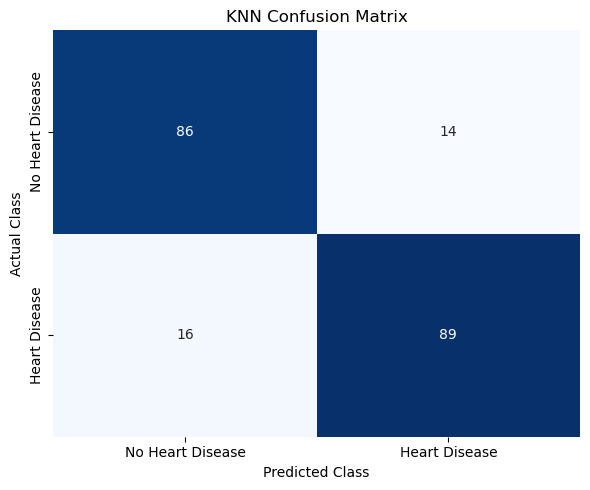

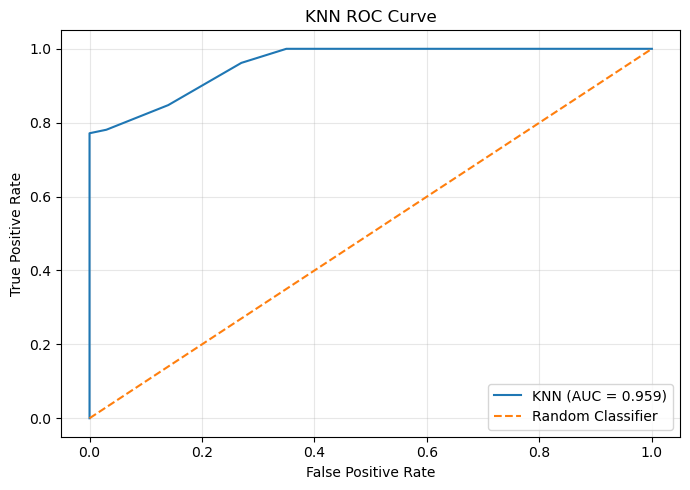

In [69]:
# Confusion Matrix and ROC Curve for KNN
from sklearn.metrics import confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
# Confusion matrix
knn_cm = confusion_matrix(y_test, knn_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Heart Disease", "Heart Disease"],
    yticklabels=["No Heart Disease", "Heart Disease"]
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()
# ROC curve
knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_prob)
knn_roc_auc = auc(knn_fpr, knn_tpr)
plt.figure(figsize=(7, 5))
plt.plot(
    knn_fpr,
    knn_tpr,
    label=f"KNN (AUC = {knn_roc_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Discussion

The KNN model successfully categorised 86 patients who did not have heart disease and 89 patients who had heart disease. It predicted 14 false positives and 16 false negatives, for a total of 175 valid predictions out of 205 test records.

The model obtained an accuracy of 85.37%, precision of 86.41%, recall of 84.76%, F1 Score of 85.58%, and AUC of 95.90%. The recreated accuracy is close to the 85.85% accuracy reported for KNN in the selected study [1].

The ROC curve indicates a very good separation between the two target groups with an AUC of 0.959. However, like with the other baseline models, these results should be taken with a grain of salt as the baseline train-test split has a significant amount of duplication overlap. The subsequent duplicate controlled experiment offers a more rigorous test of KNN performance on unique observations.

## 5. Stacking Ensemble Reproduction

The selected paper’s key contribution is an ensemble strategy based on stacking to predict cardiac disease. The separate classifiers are trained and then the underlying models are combined via stacking, such that their predictions may be used by a meta-classifier to make the final prediction [1] [5].

Here I duplicate the stacking strategy and analyse it using the same measures of Accuracy, Precision, Recall, F1 Score and AUC used for the individual models.

In [72]:
# Reproduce the paper's stacking ensemble approach
from sklearn.ensemble import StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
# Base classifiers
base_models = [
    ('lr', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ('dt', DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ('rf', RandomForestClassifier(random_state=RANDOM_STATE)),
    ('xgb', XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric='logloss'
    )),
    ('nb', GaussianNB()),
    ('knn', KNeighborsClassifier())
]
# Meta-classifier
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)
# Train the stacking model using the scaled training data
stack_model.fit(X_train_scaled, y_train)
# Evaluate on the scaled test data
stack_pred, stack_score = evaluate_model(
    "Stacking Ensemble",
    stack_model,
    X_test_scaled,
    y_test
)

Stacking Ensemble Results
-----------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000
AUC      : 1.0000


### Discussion

The **Stacking Ensemble** has **perfect accuracy** with all metrics (Accuracy, Precision, Recall, F1 Score, and AUC) scoring **1.0000**. This implies that the ensemble successfully classified all of the current test set observations.

The result coincides with the good performance of **Random Forest and XGboost. But it should be translated with caution as the previous study revealed that **98.54% of the test rows were represented by identical records in the training data**.

Therefore, these perfect scores indicate good performance on the present baseline split but **not on truly unseen patient records**. The experiment with double control will test this later.

### 5.1 Stacking Ensemble Evaluation

After replicating the stacking ensemble I further test the classification behaviour using confusion matrix and ROC curve. The confusion matrix gives us a clear picture of how many forecasts were right and wrong for heart disease and no heart disease cases, rather than just looking at the accuracy.

The ROC curve is also presented to analyse the performance of the stacking model to discriminate the two target classes at different classification thresholds. The accompanying AUC value is an extra measure of this discrimination capacity. These results along with the Accuracy, Precision, Recall and F1 Score are reviewed for a more full evaluation of the reproduced stacking strategy.

This evaluation is particularly significant because the baseline dataset has a large duplicate overlap between the training and test sets. Very good performance on this split should thus be considered with caution rather than taken as indication that the model will generalise as well to wholly unknown patient records.

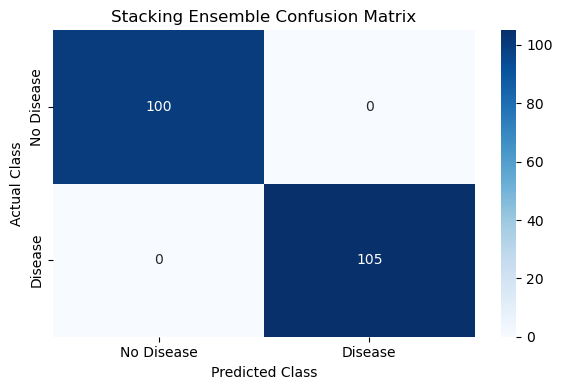

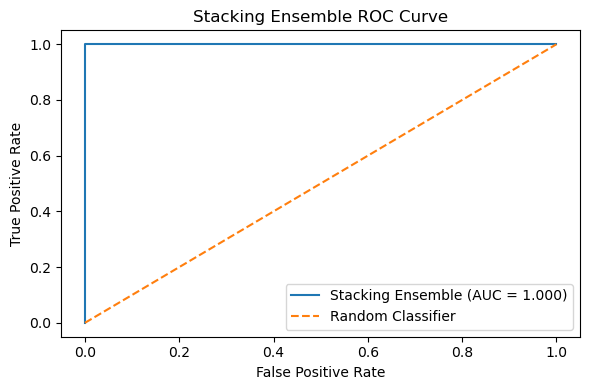

In [75]:
# Confusion matrix for the Stacking Ensemble
stack_cm = confusion_matrix(y_test, stack_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    stack_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Stacking Ensemble Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
# ROC curve for the Stacking Ensemble
stack_fpr, stack_tpr, _ = roc_curve(y_test, stack_score)
stack_auc = roc_auc_score(y_test, stack_score)

plt.figure(figsize=(6, 4))
plt.plot(
    stack_fpr,
    stack_tpr,
    label=f"Stacking Ensemble (AUC = {stack_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.title("Stacking Ensemble ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

### Discussion

The Stacking Ensemble achieved faultless performance on the baseline test set, with all metrics Accuracy, Precision, Recall and F1 Score equal to 1.0000. The confusion matrix validates this conclusion as all the 100 patients without heart disease and 105 patients with heart disease were classified properly. No false-positive or false-negative predictions were observed.

The ROC curve similarly demonstrates complete separation between the two target classes with AUC = 1.000. This shows that the stacking model was able to identify between heart disease and no heart disease instances on this test set without any misclassification.

But these findings should be regarded with caution. As seen in the duplicate analysis earlier, 98.54% of the test rows had identical entries in the training data. The flawless outcome is therefore not always an indication that the ensemble will generalise similarly well to truly unseen patient records. A following experiment with duplicate control is required to give a more realistic estimate of the generalisation performance of the model.

### 5.2 Comparison of Reproduced Models

To compare the various machine learning methods in a fair way, the performance of the reproduced individual classifiers and the stacking ensemble is summed by Accuracy, Precision, Recall, F1 Score and AUC. The evaluation measures employed during the reproduction are mainly:

Also, the recreated results are compared with the reported results in the original study. This comparison is crucial since an exact reproduction is not always expected when specifics such as random splitting, model initialisation and some parameter values are not fully described. So accuracy is not the only thing considered. We will look at the difference between the published and recreated outcomes.

In [78]:
# Add the executed KNN result to the reproduced model results
# Remove an existing KNN entry first to avoid duplicates when rerunning
model_results = [
    result for result in model_results
    if result["Model"] != "KNN"
]
model_results.append({
    "Model": "KNN",
    "Accuracy": knn_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1,
    "AUC": knn_auc
})
# Create a comparison table for all reproduced models
comparison_df = pd.DataFrame(model_results)
# Arrange the metrics in a clear order
comparison_df = comparison_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUC"
    ]
]
# Set the model order to match the selected study
model_order = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "Naive Bayes",
    "KNN",
    "Stacking Ensemble"
]

comparison_df["Model"] = pd.Categorical(
    comparison_df["Model"],
    categories=model_order,
    ordered=True
)
comparison_df = (
    comparison_df
    .sort_values("Model")
    .reset_index(drop=True)
)
# Convert model names back to normal strings
comparison_df["Model"] = comparison_df["Model"].astype(str)
# Convert metric values to percentages for easier interpretation
comparison_display = comparison_df.copy()
for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]:
    comparison_display[metric] = (
        comparison_display[metric] * 100
    ).round(2)
# Display final comparison table
print("Comparison of Reproduced Model Performance")
display(comparison_display)

Comparison of Reproduced Model Performance


,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,Logistic Regression,83.41,79.34,91.43,84.96,92.86
1,Decision Tree,98.54,100.00,97.14,98.55,98.57
2,Random Forest,100.00,100.00,100.00,100.00,100.00
3,XGBoost,100.00,100.00,100.00,100.00,100.00
4,Naive Bayes,82.93,80.70,87.62,84.02,90.43
5,KNN,85.37,86.41,84.76,85.58,95.90
6,Stacking Ensemble,100.00,100.00,100.00,100.00,100.00


### Discussion
The comparison reveals considerable variances in the performance of the duplicated models . Logistic Regression Accuracy 83.41%, Precision 79.34%, Recall 91.43%, F1 Score 84.96% and AUC 92.86%. The reasonably high recall shows that it found most of the positive cases in the baseline test set.

Naive Bayes obtained 82.93% accuracy and 90.43% AUC. KNN has an accuracy of 85.37%, precision of 86.41%, recall of 84.76%, F1 Score of 85.58% and AUC of 95.90%. Decision Tree had 98.54% accuracy whereas Random Forest and XGBoost got 100% for all five evaluation metrics. The Stacking Ensemble also obtained 100% accuracy, precision, recall, F1 Score and AUC.

While several models achieved very high baseline outcomes, these results should be taken with a grain of salt. The analysis of the duplicate showed that 98.54% of the baseline test records had a matching feature record in the training data. Thus the latter duplicate-controlled evaluation gives a stricter test of model performance on unique observations.

### 5.3 Comparison with the Published Paper

The reproduced results are now compared with the performance given in the original research paper [1]. This comparison allows to evaluate the degree of reproduction of the published results and the differences introduced by the experimental setup, splitting and characteristics of the dataset.

In [81]:
# Results reported in the original paper
paper_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Naive Bayes",
        "KNN",
        "Stacking Ensemble"
    ],
    "Paper Accuracy": [
        84.39,
        92.68,
        92.68,
        90.73,
        84.39,
        85.85,
        98.53
    ],

    "Paper Precision": [
        81.96,
        97.02,
        91.30,
        91.74,
        82.50,
        86.48,
        100.00
    ],

    "Paper Recall": [
        90.90,
        89.09,
        95.45,
        90.90,
        90.00,
        87.27,
        97.27
    ],

    "Paper F1 Score": [
        86.20,
        92.89,
        93.33,
        91.32,
        86.08,
        86.87,
        98.61
    ],

    "Paper AUC": [
        92.04,
        97.02,
        97.34,
        98.30,
        91.85,
        93.04,
        98.80
    ]
})


# Prepare reproduced results from Section 5.2
reproduced_results = comparison_display.copy()

# Remove duplicate model entries if present
reproduced_results = reproduced_results.drop_duplicates(
    subset="Model",
    keep="first"
)

# Rename reproduced metric columns
reproduced_results = reproduced_results.rename(columns={
    "Accuracy": "Reproduced Accuracy",
    "Precision": "Reproduced Precision",
    "Recall": "Reproduced Recall",
    "F1 Score": "Reproduced F1 Score",
    "AUC": "Reproduced AUC"
})


# Merge published and reproduced results
paper_comparison = pd.merge(
    paper_results,
    reproduced_results,
    on="Model",
    how="inner"
)


# Arrange columns for direct comparison
paper_comparison = paper_comparison[
    [
        "Model",
        "Paper Accuracy",
        "Reproduced Accuracy",
        "Paper Precision",
        "Reproduced Precision",
        "Paper Recall",
        "Reproduced Recall",
        "Paper F1 Score",
        "Reproduced F1 Score",
        "Paper AUC",
        "Reproduced AUC"
    ]
]


# Display final comparison table
print("Published Paper vs Reproduced Results")
display(paper_comparison)

Published Paper vs Reproduced Results


,Model,Paper Accuracy,Reproduced Accuracy,Paper Precision,Reproduced Precision,Paper Recall,Reproduced Recall,Paper F1 Score,Reproduced F1 Score,Paper AUC,Reproduced AUC
0,Logistic Regression,84.39,83.41,81.96,79.34,90.90,91.43,86.20,84.96,92.04,92.86
1,Decision Tree,92.68,98.54,97.02,100.00,89.09,97.14,92.89,98.55,97.02,98.57
2,Random Forest,92.68,100.00,91.30,100.00,95.45,100.00,93.33,100.00,97.34,100.00
3,XGBoost,90.73,100.00,91.74,100.00,90.90,100.00,91.32,100.00,98.30,100.00
4,Naive Bayes,84.39,82.93,82.50,80.70,90.00,87.62,86.08,84.02,91.85,90.43
5,KNN,85.85,85.37,86.48,86.41,87.27,84.76,86.87,85.58,93.04,95.90
6,Stacking Ensemble,98.53,100.00,100.00,100.00,97.27,100.00,98.61,100.00,98.80,100.00


### Discussion

The results obtained in this investigation are different from those reported in the original study. Logistic Regression attained an accuracy of 83.41% compared to 84.39% in the published study. It reproduced a precision of 79.34% , recall of 91.43% , F1 Score of 84.96% and AUC of 92.86% In general it performed in a way similar to the reported results [1].

Naive Bayes likewise provided comparable results with a reproduction accuracy of 82.93% versus the published 84.39%. Decision Tree better performed in the baseline reproduction, with an increase in accuracy from 92.68% to 98.54%. Random Forest boosted its accuracy from 92.68% to 100% while XGBoost increased its accuracy from 90.73% to 100% [1].

The results of KNN were similar to the results reported in the original study. Its reproduced accuracy was 85.37% as against the published accuracy of 85.85%. Precision was 86.41% vs 86.48%, although recall declined from 87.27% to 84.76% and F1 Score from 86.87% to 85.58%. But the reproduced AUC increased from 93.04% to 95.90% [1].

The Stacking Ensemble obtained 100% accuracy for the baseline reproduction, as opposed to 98.53% reported in the original study. The recreated precision, recall and F1 Score were also 100% and the reproduced AUC was 100% against the stated AUC of 98.80% [1].

These differences should be interpreted with caution. The duplicate analysis shows that 98.54% of the baseline test records have an identical feature record in the training data . Therefore, the very high baseline results, especially for the tree-based models and the Stacking Ensemble, may be unduly optimistic in estimating performance on truly unknown patient records. This motivates the redundant controlled evaluation in Section 6.

### 5.4 Visual Comparison of Published and Reproduced Accuracy

To facilitate the interpretation of the discrepancies between published and reproduced results, we compare the accuracy of each reproduced model visually to the comparable accuracy reported in the original work [1].

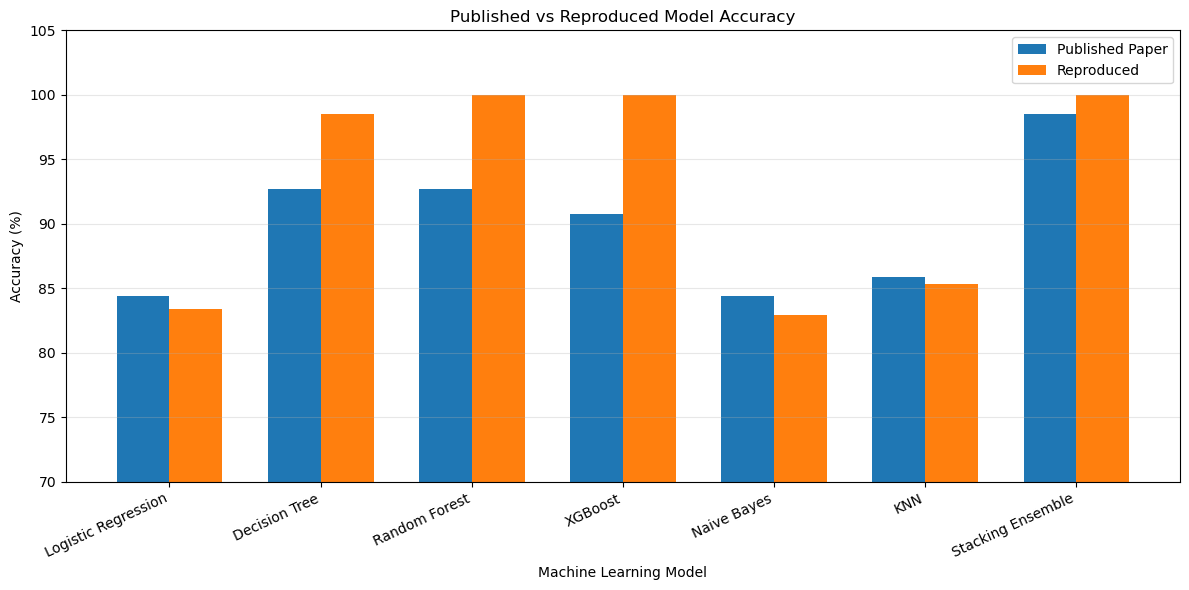

In [84]:
import numpy as np
import matplotlib.pyplot as plt
models = paper_comparison["Model"]
paper_accuracy = paper_comparison["Paper Accuracy"]
reproduced_accuracy = paper_comparison["Reproduced Accuracy"]
x = np.arange(len(models))
width = 0.35
plt.figure(figsize=(12, 6))
plt.bar(
    x - width/2,
    paper_accuracy,
    width,
    label="Published Paper"
)
plt.bar(
    x + width/2,
    reproduced_accuracy,
    width,
    label="Reproduced"
)
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Published vs Reproduced Model Accuracy")
plt.xticks(x, models, rotation=25, ha="right")
plt.ylim(70, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Discussion

The graphical comparison demonstrates the differences between the published and recreated model accuracies. The re-implementation of Logistic Regression resulted in an accuracy of 83.41% compared to the published accuracy of 84.39% whereas Naive Bayes resulted in an accuracy of 82.93% and the reported accuracy is 84.39% [1].

KNN provided one of the closest outcomes to the published study. The published KNN accuracy was 85.85% while the recreated model reached 85.37% with a tiny discrepancy of 0.48 percentage points [1].

The tree-based models have bigger disparities. Decision Tree improved from a published accuracy of 92.68% to 98.54% . Random Forest improved from 92.68% to 100% while XGBoost improved from 90.73% to 100%. [1] The Stacking Ensemble improved from the published accuracy of 98.53% [1] to 100% in the baseline reproduction.

The high baseline findings should be regarded with caution, as the duplicate analysis showed that 98.54% of the baseline test records contain an identical feature record in the training data. Thus, near-perfect outcomes of some models may not be an indication of their performance on truly unseen patient information. This motivates the duplicate-controlled assessment in Section 6 .

## 6. Proposed Machine Learning Solution

The scores were extremely high for the initial train/test split, but nearly all the records in the test set had a duplicate feature record in the train set. I therefore needed to verify the performance of the models with a unique record evaluation.
I eliminated exact duplicate rows and ran the same six classifiers and stacking ensemble on them. I initially ran a single train/test split stratification before running the same six classifiers using repeated stratified five-fold cross-validation. The subsequent sections will describe the methodology and its comparison to the previous reproduction.

### 6.1 Identified Limitation and Motivation

A notable constraint noticed during the reproduction was the occurrence of duplicate patient information in the dataset. In the baseline random train-test split, 98.54% of the test records had an exact feature record in the training set. This results in data leakage due to the small amount of novel information available in the test set [3].

This issue is particularly noteworthy because the strongest reproduced models showed abnormally high outcomes. The Random Forest, XGBoost and the Stacking Ensemble achieved 100% accuracy on the baseline test set while the published study reported 92.68%, 90.73% and 98.53% accuracy correspondingly [1].

To overcome this restriction I suggest a duplicate-controlled experimental technique. Exact duplicate records will be deleted before the training and testing sets are generated. Then a new stratified split will be made, so that the evaluation is done on unique patient data while keeping the target-class distribution . Then the same categorisation methods and assessment metrics are applied, which allows for a direct comparison of the duplicate-controlled results with the recreated baseline and the published results.

This experiment does not only aim to get a higher accuracy. Instead, it seeks to provide a more realistic evaluation of the models’ capacity to generalise to patient records that are not repeated throughout the training and test sets.

In [88]:
# Reconstruct the complete dataset from the existing train and test data
X_full = pd.concat([X_train, X_test], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_test], axis=0).reset_index(drop=True)
# Combine features and target into one dataframe
df_full = X_full.copy()
df_full["target"] = y_full
print("Original dataset shape:", df_full.shape)
# Count exact duplicate rows
duplicate_count = df_full.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df_full)) * 100
print("Exact duplicate rows:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")
# Remove exact duplicate rows
df_unique = df_full.drop_duplicates().reset_index(drop=True)
print("\nDataset shape after duplicate removal:", df_unique.shape)
print("Rows removed:", len(df_full) - len(df_unique))
# Verify duplicate removal
remaining_duplicates = df_unique.duplicated().sum()
print("Remaining exact duplicates:", remaining_duplicates)
# Check target distribution
print("\nTarget distribution after duplicate removal:")
print(df_unique["target"].value_counts())
print("\nTarget distribution (%):")
print(
    (df_unique["target"].value_counts(normalize=True) * 100).round(2)
)

Original dataset shape: (1025, 14)
Exact duplicate rows: 723
Duplicate percentage: 70.54%

Dataset shape after duplicate removal: (302, 14)
Rows removed: 723
Remaining exact duplicates: 0

Target distribution after duplicate removal:
target
1    164
0    138
Name: count, dtype: int64

Target distribution (%):
target
1    54.3
0    45.7
Name: proportion, dtype: float64


### Discussion

The duplicate analysis revealed a large number of repeated information in the dataset. Of the original 1,025 records, 723 rows were exact duplicates, or 70.54% of the entire dataset. After these repeated records were deleted, only 302 unique patient records remained and the verification showed no exact copies remained.

Importantly, the duplications elimination process did not cause a serious class imbalance. Out of the total of 302 distinct records, 164 (54.3%) are in the heart disease category and 138 (45.7%) are in the no-heart-disease category. Thus, both target classes are still represented enough for the following experiment.

These data add further evidence that the perfect baseline results should be evaluated carefully. The original dataset contains many duplicate records, therefore a normal random training and test split can result in identical patient profiles. By removing these duplicates before separating the data we arrive at a more rigorous evaluation setting, where the test observations are truly different from the training observations.

### 6.2 Duplicate-Controlled Experimental Protocol

Exact duplicate records are removed and the remaining 302 unique observations are utilised to build a new training and test set. The target variable is segregated from the 13 input features, and a stratified train-test split is used so that the proportion of heart disease and non-heart-disease cases is preserved in both subsets.

We fix a random state for reproducibility of the experiment . After the baseline reproduction, the test size is fixed at 20%. And most significantly, duplication eradication is done prior to the split. This avoids splitting the same complete records between the training and test sets.

The resulting split is then evaluated for class distribution and feature overlap before any models are trained. This imposes a tougher experimental approach to determine whether the models can generalise to unique patient observations rather than gain from repetitive records.

In [91]:
from sklearn.model_selection import train_test_split
# Separate features and target from the duplicate-controlled dataset
X_unique = df_unique.drop(columns=["target"])
y_unique = df_unique["target"]
# Create a stratified 80/20 train-test split
X_train_unique, X_test_unique, y_train_unique, y_test_unique = train_test_split(
    X_unique,
    y_unique,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_unique
)
print("Duplicate-Controlled Train/Test Split")
print("-" * 40)
print("Training set shape:", X_train_unique.shape)
print("Test set shape:", X_test_unique.shape)
print("\nTraining target distribution:")
print(y_train_unique.value_counts())
print("\nTest target distribution:")
print(y_test_unique.value_counts())
# Check whether any identical feature rows appear in both sets
train_rows = set(map(tuple, X_train_unique.to_numpy()))
test_rows = set(map(tuple, X_test_unique.to_numpy()))
overlap = train_rows.intersection(test_rows)
print("\nIdentical feature rows shared between train and test:", len(overlap))
overlap_percentage = (
    len(overlap) / len(X_test_unique) * 100
)
print(f"Train-test duplicate overlap: {overlap_percentage:.2f}%")

Duplicate-Controlled Train/Test Split
----------------------------------------
Training set shape: (241, 13)
Test set shape: (61, 13)

Training target distribution:
target
1    131
0    110
Name: count, dtype: int64

Test target distribution:
target
1    33
0    28
Name: count, dtype: int64

Identical feature rows shared between train and test: 0
Train-test duplicate overlap: 0.00%


### Discussion

The duplicate-controlled dataset was split into 241 training and 61 test records with an 80/20 stratified split. Training data set has 131 cases of heart disease and 110 cases of non-heart illness. Test data set has 33 cases of heart disease, and 28 cases of non-heart disease. This means that the distribution of classes is quite balanced in both subgroups.

Most crucially, the overlap check did not find any identical feature records shared between the training and test sets, giving a train-test duplicate overlap of 0.00%. This is a huge improvement over the baseline trial, where 98.54% of the test records had an exact feature record reflected in the training data.

Thus, the new methodology provides a stricter evaluation environment. All results achieved by the following models are on truly unique test instances and not repeated instances that appear across the split. This makes the following results more suitable for the evaluation of model generalisation.

### 6.3 Model Evaluation on Duplicate-Controlled Data

We now test the identical machine learning algorithms as in the baseline reproduction on the duplicate-controlled training and test sets. The effect of the enhanced experimental technique can be evaluated without affecting the core modelling objective by using the same model families and evaluation metrics.

Each model is trained on the 241 unique records and tested on the 61 unique records. The performance is evaluated in terms of Accuracy, Precision, Recall, F1 Score and AUC. The stacking ensemble still use five-fold cross-validation to get the meta-level predictions.

The results from this experiment will be compared subsequently with the original baseline reproduction and results stated in the published study [1].

In [94]:
# Apply Min-Max normalisation to the duplicate-controlled split
# The scaler is fitted only on the training data to avoid test-data leakage
unique_scaler = MinMaxScaler()
X_train_unique_scaled = unique_scaler.fit_transform(X_train_unique)
X_test_unique_scaled = unique_scaler.transform(X_test_unique)
# Convert scaled arrays back to DataFrames
X_train_unique_scaled = pd.DataFrame(
    X_train_unique_scaled,
    columns=X_train_unique.columns,
    index=X_train_unique.index
)
X_test_unique_scaled = pd.DataFrame(
    X_test_unique_scaled,
    columns=X_test_unique.columns,
    index=X_test_unique.index
)
# Verify training-data scaling
print("Duplicate-controlled training minimum:",
      X_train_unique_scaled.min().min())
print("Duplicate-controlled training maximum:",
      X_train_unique_scaled.max().max())
# Models for duplicate-controlled evaluation
unique_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ),

    "Naive Bayes": GaussianNB(),

    "KNN": KNeighborsClassifier()
}
# Store duplicate-controlled results
unique_results = []
# Train and evaluate each individual model
for model_name, model in unique_models.items():

    model.fit(X_train_unique_scaled, y_train_unique)

    y_pred = model.predict(X_test_unique_scaled)
    y_prob = model.predict_proba(X_test_unique_scaled)[:, 1]

    unique_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_unique, y_pred),
        "Precision": precision_score(y_test_unique, y_pred),
        "Recall": recall_score(y_test_unique, y_pred),
        "F1 Score": f1_score(y_test_unique, y_pred),
        "AUC": roc_auc_score(y_test_unique, y_prob)
    })


# Build the stacking ensemble using the same six base classifiers
unique_base_models = [
    (
        "lr",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    ),

    (
        "dt",
        DecisionTreeClassifier(
            random_state=RANDOM_STATE
        )
    ),

    (
        "rf",
        RandomForestClassifier(
            random_state=RANDOM_STATE
        )
    ),

    (
        "xgb",
        XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="logloss"
        )
    ),

    (
        "nb",
        GaussianNB()
    ),

    (
        "knn",
        KNeighborsClassifier()
    )
]


# Create stacking classifier
unique_stack_model = StackingClassifier(
    estimators=unique_base_models,
    final_estimator=LogisticRegression(
        max_iter=1000
    ),
    cv=5
)


# Train stacking ensemble using Min-Max normalised features
unique_stack_model.fit(
    X_train_unique_scaled,
    y_train_unique
)


# Evaluate stacking ensemble
stack_unique_pred = unique_stack_model.predict(
    X_test_unique_scaled
)

stack_unique_prob = unique_stack_model.predict_proba(
    X_test_unique_scaled
)[:, 1]


# Add stacking results
unique_results.append({
    "Model": "Stacking Ensemble",
    "Accuracy": accuracy_score(
        y_test_unique,
        stack_unique_pred
    ),
    "Precision": precision_score(
        y_test_unique,
        stack_unique_pred
    ),
    "Recall": recall_score(
        y_test_unique,
        stack_unique_pred
    ),
    "F1 Score": f1_score(
        y_test_unique,
        stack_unique_pred
    ),
    "AUC": roc_auc_score(
        y_test_unique,
        stack_unique_prob
    )
})


# Create results table
unique_results_df = pd.DataFrame(unique_results)


# Convert metrics to percentages for display
unique_results_display = unique_results_df.copy()

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]:
    unique_results_display[metric] = (
        unique_results_display[metric] * 100
    ).round(2)
print("\nDuplicate-Controlled Model Performance")
display(unique_results_display)

Duplicate-controlled training minimum: 0.0
Duplicate-controlled training maximum: 1.0

Duplicate-Controlled Model Performance


,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,Logistic Regression,77.05,74.36,87.88,80.56,90.69
1,Decision Tree,77.05,78.79,78.79,78.79,76.89
2,Random Forest,83.61,84.85,84.85,84.85,89.72
3,XGBoost,81.97,84.38,81.82,83.08,89.50
4,Naive Bayes,81.97,80.56,87.88,84.06,88.74
5,KNN,81.97,80.56,87.88,84.06,88.80
6,Stacking Ensemble,83.61,81.08,90.91,85.71,93.40


### Discussion

The evaluation with duplicate control resulted in more realistic outcomes than the first baseline trial. Exact duplicate records were deleted and Min-Max normalisation was applied only to the training data before assessing the models. This gives a more stringent test with unique observations and standardised pre-processing.

The accuracy of Logistic Regression is 77.05%, precision is 74.36%, recall is 87.88%, F1 Score is 80.56% and AUC is 90.69%. Random Forest gave greatest accuracy of 83.61% followed by F1 Score of 84.85% and AUC of 89.72%. XGBoost with Naive Bayes had an accuracy of 81.97% Decision Tree classified with 77.05%.

KNN showed an Accuracy of 81.97%, Precision of 80.56%, Recall of 87.88%, F1 Score of 84.06% and AUC of 88.80% after duplicate control. This shows how KNN performed when duplicate records were controlled in the evaluation.

The accuracy of Stacking Ensemble was 83.61% with precision 81.08%, recall 90.91%, F1 Score 85.71% and AUC 93.40%. The stacking model, however, showed the best AUC compared to the other models assessed, which suggests that the overall discriminating between the two target classes was better than the other models, while the accuracy was the same as Random Forest.

Compared to the very high baseline findings, the reduced performance with duplicate-control shows why the duplicate-control methodology is necessary. The Identical records are excluded from the training and test sets to produce a more cautious and realistic assessment of the model’s likely performance on unseen data.

### 6.3.1 Repeated Cross-Validation on Unique Records

One output is possible based on the 61-record test set, but another partition would yield a different score. To examine the reliability of the findings, I additionally analyze the models on 302 unique records by using repeated stratified five-fold cross-validation. I repeat the five folds three times, each time using a new partition. The folds are the same for each model, and Min-Max scaling is computed individually in each training fold. Accuracy, Precision, Recall, F1 Score, and AUC are averaged and their standard deviation is reported. I retain the first 61-record run result to demonstrate how a particular split looks, but employ cross-validation to see how results vary depending on other data splits for this tiny dataset [4].

In [97]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

# Five folds, repeated three times, give 15 test results per model.
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1 Score": "f1",
    "AUC": "roc_auc"
}

# Use the models already defined for the duplicate-controlled experiment.
# The pipeline fits Min-Max scaling again within each training fold.
cv_models = {
    name: make_pipeline(MinMaxScaler(), clone(model))
    for name, model in unique_models.items()
}
cv_models["Stacking Ensemble"] = make_pipeline(
    MinMaxScaler(),
    clone(unique_stack_model)
)

cv_rows = []

for name, model in cv_models.items():
    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X_unique,
        y_unique,
        cv=repeated_cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    row = {"Model": name}
    for metric in scoring:
        values = scores["test_" + metric] * 100
        row[metric + " Mean"] = values.mean()
        row[metric + " SD"] = values.std(ddof=1)

    cv_rows.append(row)

repeated_cv_results = pd.DataFrame(cv_rows)
display(repeated_cv_results.round(2))

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: XGBoost
Evaluating: Naive Bayes
Evaluating: KNN
Evaluating: Stacking Ensemble


,Model,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Score Mean,F1 Score SD,AUC Mean,AUC SD
0,Logistic Regression,82.56,3.86,80.80,5.20,89.64,4.96,84.83,3.24,90.46,3.36
1,Decision Tree,74.73,6.37,77.18,5.56,76.05,9.23,76.41,6.63,74.58,6.26
2,Random Forest,82.23,4.36,81.80,5.49,87.22,7.33,84.15,4.05,90.21,3.08
3,XGBoost,79.69,3.80,80.58,5.32,83.14,6.65,81.59,3.62,87.59,3.34
4,Naive Bayes,81.68,3.96,81.89,4.34,85.36,6.35,83.44,3.80,89.45,3.75
5,KNN,80.71,6.42,81.34,6.78,84.37,9.78,82.45,6.02,86.25,5.46
6,Stacking Ensemble,82.57,4.06,81.92,4.85,87.62,6.41,84.48,3.71,90.51,3.43


### Discussion

As opposed to the one single 61-record test split, the repeated cross-validation offers a better illustration of the models' performances. During the 15 validation splits, the stacking model achieved an average accuracy of 82.57%, its standard deviation being 4.06%. Its average F1 Score was 84.48% and its average AUC – 90.51%. Compared to the previous single-split stacking model, the average accuracy was slightly lower (83.61%), however, one data point is not enough to illustrate the variation of the results with different records used for training and testing.

Random Forest and Logistic Regression models showed almost the same mean accuracy scores - 82.23% and 82.56%, correspondingly. Therefore, there was no evident improvement of the average accuracy of the model in comparison with the separate models' average accuracies. Decision Tree model showed the lowest mean accuracy of 74.73%. These results are consistent with the general conclusion about the significant difference between the performance of the models in the unique records situation and the nearly perfect results from the duplicate-overlapping Part 1 split. As these scores were obtained under different evaluation protocol, their comparison cannot be regarded as a controlled improvement estimate of any particular model.

### 6.4 Baseline vs Duplicate-Controlled Evaluation

A comparison between the original replication and single-split results on unique records is provided to demonstrate how the scores vary according to the new scoring system. The table contains the names of the models and accuracy scores from both sets of experiments.
It is a comparison of two experimental configurations, not an examination of the effects of duplicates' elimination alone. The number of observations in the unique-record experiment is smaller, as well as the new train/test split has been made. Therefore, the results of this experiment must be employed to examine the generalisation ability of the original high scores, not its causes.

Baseline vs Duplicate-Controlled Accuracy


,Model,Accuracy Baseline,Accuracy Duplicate-Controlled,Accuracy Change
0,Logistic Regression,83.41,77.05,-6.36
1,Decision Tree,98.54,77.05,-21.49
2,Random Forest,100.00,83.61,-16.39
3,XGBoost,100.00,81.97,-18.03
4,Naive Bayes,82.93,81.97,-0.96
5,KNN,85.37,81.97,-3.40
6,Stacking Ensemble,100.00,83.61,-16.39


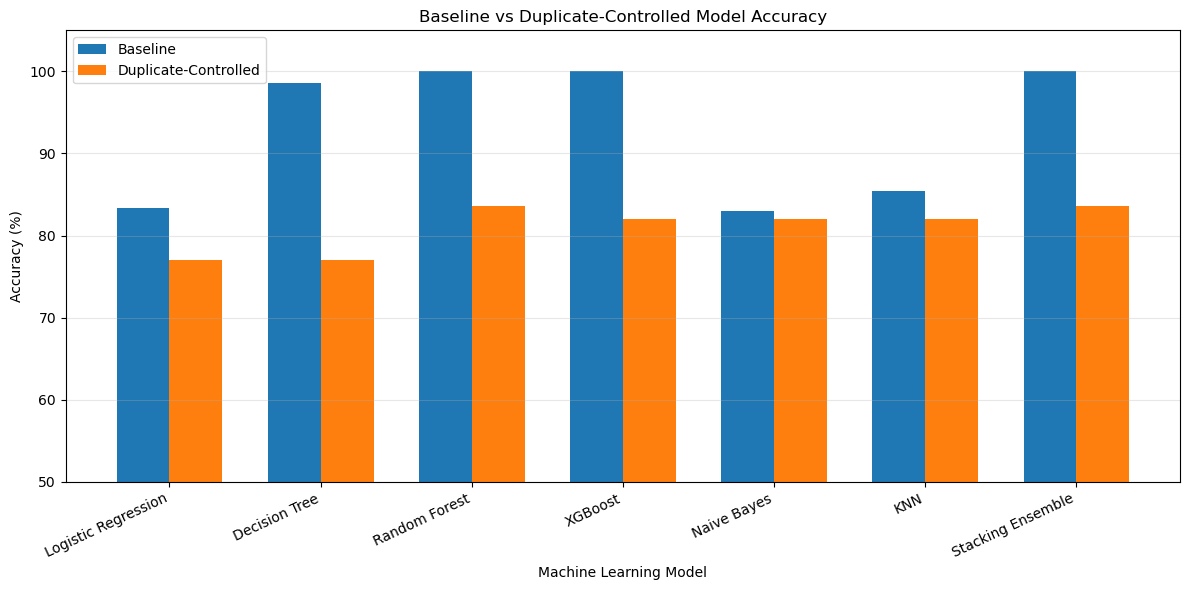

In [100]:
# Prepare baseline results
baseline_comparison = comparison_display.copy()

# Remove duplicate model entries if present
baseline_comparison = baseline_comparison.drop_duplicates(
    subset="Model",
    keep="first"
)
# Prepare duplicate-controlled results
controlled_comparison = unique_results_display.copy()

# Merge models available in both experiments
baseline_vs_controlled = pd.merge(
    baseline_comparison,
    controlled_comparison,
    on="Model",
    suffixes=(" Baseline", " Duplicate-Controlled")
)

# Calculate the change in accuracy
baseline_vs_controlled["Accuracy Change"] = (
    baseline_vs_controlled["Accuracy Duplicate-Controlled"]
    - baseline_vs_controlled["Accuracy Baseline"]
).round(2)

# Select the main columns for a clear comparison table
accuracy_comparison = baseline_vs_controlled[
    [
        "Model",
        "Accuracy Baseline",
        "Accuracy Duplicate-Controlled",
        "Accuracy Change"
    ]
]

print("Baseline vs Duplicate-Controlled Accuracy")
display(accuracy_comparison)
# Visual comparison
import numpy as np
import matplotlib.pyplot as plt

models = accuracy_comparison["Model"]
baseline_accuracy = accuracy_comparison["Accuracy Baseline"]
controlled_accuracy = accuracy_comparison["Accuracy Duplicate-Controlled"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    baseline_accuracy,
    width,
    label="Baseline"
)

plt.bar(
    x + width/2,
    controlled_accuracy,
    width,
    label="Duplicate-Controlled"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Duplicate-Controlled Model Accuracy")
plt.xticks(x, models, rotation=25, ha="right")
plt.ylim(50, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Discussion

Most of the models showed lesser accuracy in the unique record experiment compared to the original reproduction. Decision Tree went down from 98.54% to 77.05%, whereas Random Forest and stacking went down from 100% to 83.61%. As seen from the table, these are the discrepancies, but one cannot say what the reason behind them is.
In the original split, out of the 205 test records, 202 records had an identical feature record in the training set. The revised split had no such overlap. Moreover, it included lesser records and a different train/test split. All these combined make me feel that the nearly perfect baseline accuracy scores might not serve as good indicators of accuracy for new patients.The results obtained through cross-validation in Section 6.3.1 provide more clarity on performance variations with respect to different data splits.

### 6.5 Detailed Evaluation of the Duplicate-Controlled Stacking Ensemble


The Stacking Ensemble is explored in more depth as it is the major ensemble method that is reproduced from the selected research paper [1]. The model is assessed under the duplicate-controlled methodology, utilising a confusion matrix and ROC curve, to analyse its classification mistakes and its capacity to distinguish between heart-disease and non-heart-disease instances.

This analysis provides more information than accuracy alone and allows to get an idea of the behaviour of the stacking strategy when assessed on unique patient records.

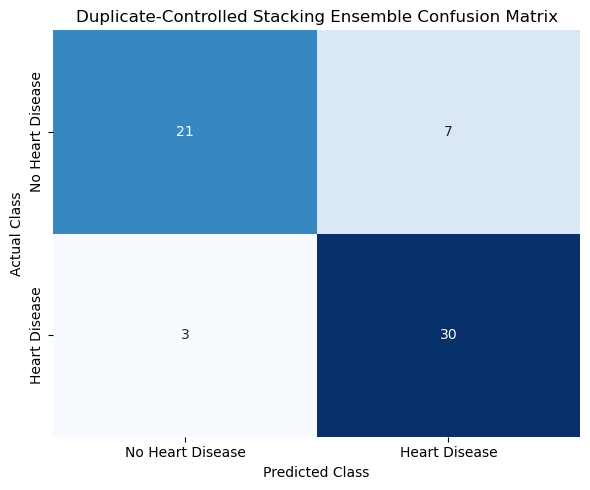

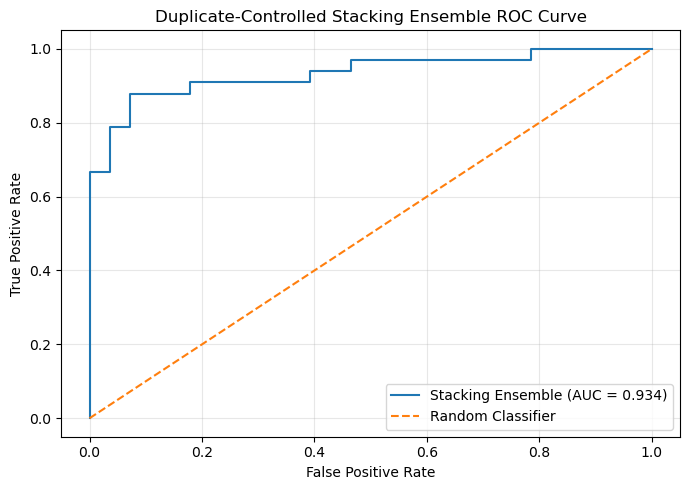

In [103]:
from sklearn.metrics import confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
# Confusion matrix for duplicate-controlled stacking ensemble
cm_unique_stack = confusion_matrix(
    y_test_unique,
    stack_unique_pred
)
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_unique_stack,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Heart Disease", "Heart Disease"],
    yticklabels=["No Heart Disease", "Heart Disease"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Duplicate-Controlled Stacking Ensemble Confusion Matrix")

plt.tight_layout()
plt.show()
# ROC curve for duplicate-controlled stacking ensemble
fpr_unique, tpr_unique, _ = roc_curve(
    y_test_unique,
    stack_unique_prob
)
roc_auc_unique = auc(
    fpr_unique,
    tpr_unique
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_unique,
    tpr_unique,
    label=f"Stacking Ensemble (AUC = {roc_auc_unique:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Duplicate-Controlled Stacking Ensemble ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Discussion

The duplicate-controlled Stacking Ensemble recognised accurately 21 individuals without heart disease and 30 patients with heart illness . Of the 61 distinct test records, 7 were predicted as false positives and 3 were predicted as false negatives. This led to 51 right classifications and 10 misclassifications.

The low number of false negatives corresponds to the model’s recall of 90.91%, indicating that 30 out of the 33 positive cases in the test set were properly detected. The overall accuracy was 83.61 percent.

The ROC analysis showed an AUC of 93.40% which indicates that the Stacking Ensemble has a good capacity to identify the two target classes after the exact duplicate records were eliminated and Min-Max normalisation was performed.

To summarise, the duplicate-controlled evaluation indicates that the model is no longer flawless, but still gives useful classification performance on unique test observations. This provides a more reliable signal of generalisation than the initial baseline evaluation with significant train-test duplication overlap.

### 6.6 Final Comparison with Published and Baseline Results

The last experiment contrasts the duplicate-controlled findings with the baseline reproduction and the results presented in the original study [1]. This gives a full picture of how the evaluation evolved in the published study, first reproduction and the planned duplicate-controlled technique.

We utilise accuracy for the visual comparison, as it gives a concise summary of the change across the three experimental settings. The wider interpretation also takes into account Precision, Recall, F1 Score and AUC from the prior evaluations.
The published accuracy values used in the following comparison are taken from Table 11 of the original study [1].

,Model,Published Accuracy (%),Baseline Reproduction (%),Duplicate-Controlled (%)
0,Logistic Regression,84.39,83.41,77.05
1,Decision Tree,92.68,98.54,77.05
2,Random Forest,92.68,100.00,83.61
3,XGBoost,90.73,100.00,81.97
4,Naive Bayes,84.39,82.93,81.97
5,KNN,85.85,85.37,81.97
6,Stacking Ensemble,98.53,100.00,83.61


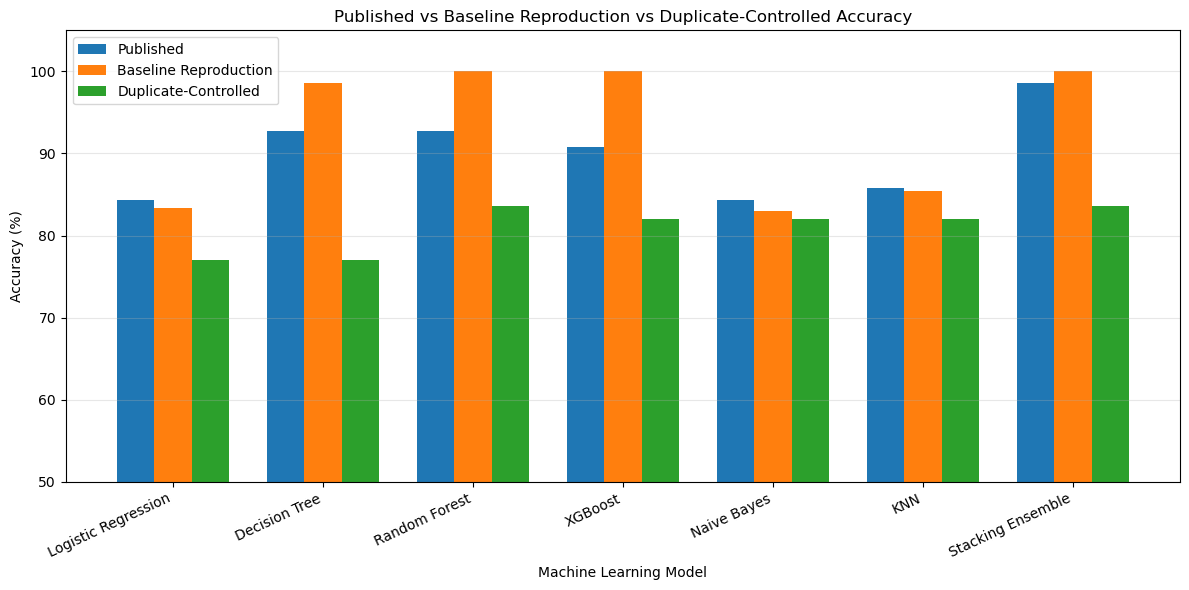

In [106]:
# Final comparison: Published vs Baseline Reproduction vs Duplicate-Controlled
models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "Naive Bayes",
    "KNN",
    "Stacking Ensemble"
]

# Accuracy values reported in the selected paper
published_accuracy = [
    84.39,
    92.68,
    92.68,
    90.73,
    84.39,
    85.85,
    98.53
]

# Accuracy obtained from the baseline reproduction
baseline_accuracy = [
    83.41,
    98.54,
    100.00,
    100.00,
    82.93,
    85.37,
    100.00
]
# Accuracy obtained after duplicate removal and Min-Max normalisation
duplicate_controlled_accuracy = [
    77.05,
    77.05,
    83.61,
    81.97,
    81.97,
    81.97,
    83.61
]

# Create final comparison table
final_comparison = pd.DataFrame({
    "Model": models,
    "Published Accuracy (%)": published_accuracy,
    "Baseline Reproduction (%)": baseline_accuracy,
    "Duplicate-Controlled (%)": duplicate_controlled_accuracy
})

display(final_comparison)


# Plot final comparison
x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    published_accuracy,
    width,
    label="Published"
)

plt.bar(
    x,
    baseline_accuracy,
    width,
    label="Baseline Reproduction"
)

plt.bar(
    x + width,
    duplicate_controlled_accuracy,
    width,
    label="Duplicate-Controlled"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title(
    "Published vs Baseline Reproduction vs Duplicate-Controlled Accuracy"
)

plt.xticks(
    x,
    models,
    rotation=25,
    ha="right"
)

plt.ylim(50, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Discussion


The last comparison emphasises the discrepancies between the outcomes provided in the selected study, the baseline reproduction and the duplicate-controlled evaluation. The published accuracies were from 84.39% for Logistic Regression and Naive Bayes to 98.53% for the suggested Stacking Ensemble [1].

Some models gave far higher results for the baseline reproduction. Decision Tree gave 98.54% accuracy and Random Forest, XGBoost and Stacking Ensemble gave 100% accuracy. After duplicate control, the results were dropped to 77.05% for Decision Tree, 83.61% for Random Forest, 81.97% for XGBoost and 83.61% for the Stacking Ensemble.

In the baseline reproduction, Logistic Regression achieved 83.41% accuracy compared to the published accuracy of 84.39% [1], and 77.05% in the duplicate-controlled evaluation. Naive Bayes was rather stable going from 82.93% in the baseline reproduction to 81.97% following duplicate control, against the published accuracy of 84.39% [1].

KNN presented a different pattern. The published accuracy was 85.85%, and the baseline replica produced a fairly similar accuracy of 85.37% [1]. After duplication elimination and Min-Max normalisation it accuracy dropped to 81.97%. Thus, the repeated KNN result was close to the published result in the baseline trial, whereas the more cautious estimate on unique patient records was obtained in the stricter duplicate-controlled evaluation.

Overall, the comparison suggests that the very high baseline results should be regarded with caution. The duplicate analysis found such overlap in the original train-test split that performance on the baseline test set can seem better than performance on truly unseen data. All models gave more conservative results after duplicate elimination. Thus, the duplicate-controlled evaluation provides a more conservative estimate of model generalisation on unseen patient records.

## 7. Critical Analysis and Limitations

The reproduction and duplicate-controlled tests indicate the model performance is highly dependent on the experimental design. In the baseline reproduction, Random Forest, XGBoost and the Stacking Ensemble obtained 100% accuracy and Decision Tree achieved 98.54% accuracy. However, the duplicate analysis found 723 exact duplicate rows out of the original 1,025 data. Moreover, 98.54% of the baseline test records had a corresponding feature record in the training set.

This overlap is a critical limitation, since a test set should give an independent evaluation of the model’s performance on unseen observations. If the same patient records are part of both training and test set, the resulting performance can give an over optimistic estimation of model generalisation. This might be the reason for the very good performance of numerous models in the baseline reproduction.

To solve this issue, the duplicate-controlled experiment deleted the 723 exact duplicate rows, leaving 302 unique observations.  A stratified 80/20 split then yielded 241 training records and 61 test records with 0.00% train-test duplicate overlap. Min-Max normalisation was fitted only on the training data and then applied to the test data

Results with duplicates controlled for were more conservative. Logistic Regression and Decision Tree achieved 77.05%, Random Forest achieved 83.61%, XGBoost achieved 81.97%, Naive Bayes achieved 81.97%, KNN achieved 81.97% and Stacking Ensemble scored 83.61% accuracy. These low scores are an indication that there was variation in the performance of the models when using the unique record metric. However, due to the difference in the size of the data set and test split, it is not possible to evaluate the effect of duplicate elimination from this analysis.

Accuracy alone is not sufficient for a thorough evaluation of the categorisation performance. The duplicate controlled Stacking Ensemble obtained accuracy of 83.61%, precision of 81.08%, recall of 90.91%, F1 Score of 85.71% and AUC of 93.40%. The confusion matrix gave 21 true negatives, 30 true positives, 7 false positives and 3 false negatives. The comparatively high recall implies most positive cases in the test set were detected and the AUC indicates decent discriminating between the two classes.

The duplicate controlled strategy has certain disadvantages too. After removing duplicate records the data set was reduced to only 302 unique observations with 61 records in the final test set. Results of such a small test sample may be different for another train-test split. The fixed random state and stratification increase reproducibility but testing on a bigger independent dataset would provide better evidence of generalisation.

The proposed evaluation is similarly mainly concerned with precise duplicate records. It does not explore near-duplicate observations, probable measurement bias, variations in patient populations, or other types of dataset shift. Future work could test the models on an independent external dataset, examine near-duplicate records, and use nested cross-validation if model settings are tuned.

I also conducted three rounds of five-fold cross-validation on the same 302 patients. This produced 15 validation scores for each model. In the case of stacking, the average accuracy was 82.57%, and the standard deviation was 4.06%. These folds employ the same records again, thus the 15 validation scores are not independent patient samples. Additionally, there is a discrepancy in terms of the sample set as well as the approach between the baseline and the current experiment. The accuracy difference between them cannot, therefore, be attributed solely to eliminating duplicates.

In general, the results indicate that the most accurate numerical results are not the most reliable estimate of performance. The duplicate-controlled evaluation resulted in lower yet more conservative results on unique test observations, and so gives a more robust assessment of model generalisation than the initial baseline split.

## 8. Conclusion

The six individual models and the stacking model from the chosen paper were recreated by me. The random forest, XGBoost and stacking obtained 100% accuracy on my original test split. At the outset, these seemed to be good results. But then I realized that out of 205 records in the test split, 202 have an exact duplicate feature vector in the training set. So these cannot be taken as valid performance metrics for new patients.
It was also verified that the selection of preprocessing step affected Logistic Regression. With the same train-test split, Logistic Regression using Min-Max scaling has 83.41% accuracy, while Logistic Regression using standard scaling has 80.98% accuracy. Adding in median imputation did not make any difference since there are no missing values in the dataset. The chosen paper has reported an accuracy of 84.39% for Logistic Regression.

After discarding all exact duplicate rows, there were 302 unique entries left. Stacking was able to achieve an accuracy of 83.61% on the 61-record testing set. In order to get an estimate that would be more robust than the result obtained using a single testing set, repeated five-fold cross-validation was conducted three times on all available records. Over the course of 15 validation rounds, the mean accuracy of stacking was 82.57% (standard deviation = 4.06%), the mean F1 score was 84.48%, and the mean AUC was 90.51%. Logistic Regression and Random Forest had very similar mean accuracies of 82.56% and 82.23%.
These new findings alter my interpretation of the initial excellent results because they clearly demonstrate the variance between different splits of the data. There was no clear advantage in terms of accuracy of stacking over the strongest individual classifiers on the unique records. Due to the fact that both original and new experiments use different sets of data and validation methods, I cannot assert that removal of duplicates alone is the cause of this change in accuracy.

## 9. References

[1] M. Bhagat, A. Sharma, and P. Agarwal, “An efficient stacking-based ensemble technique for early heart attack prediction,” *Multimedia Tools and Applications*, vol. 84, pp. 36351–36375, 2025, doi: 10.1007/s11042-024-19293-7.

[2] "Heart Disease Dataset," *Kaggle*. Accessed: Sep. 29, 2026. [Online]. Available: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset

[3] S. Kaufman, S. Rosset, C. Perlich, and O. Stitelman, “Leakage in data mining: Formulation, detection, and avoidance,” ACM Transactions on Knowledge Discovery from Data, vol. 6, no. 4, 2012, doi: 10.1145/2382577.2382579.

[4] A. Vabalas, E. Gowen, E. Poliakoff, and A. J. Casson, “Machine learning algorithm validation with a limited sample size,” PLOS ONE, vol. 14, no. 11, Art. no. e0224365, 2019, doi: 10.1371/journal.pone.0224365.

[5] D. H. Wolpert, "Stacked generalization," *Neural Networks*, vol. 5, no. 2, pp. 241–259, 1992.

## GenAI Acknowledgement


This assignment uses generative AI technologies to assist with planning, clarifying concepts, providing debugging support, and improving the structure and readability of written explanations. All machine learning experiments were run and verified in the given Jupyter Notebook and the output was compared to the implemented code and the research paper used. AI-assisted recommendations were scrutinised critically and changed before inclusion in the final product. The final submission represents my understanding of the techniques, experiments and results reported in this article.